In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/aptos2019-blindness-detection/sample_submission.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train.csv
/kaggle/input/competitions/aptos2019-blindness-detection/test.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ef476be214d4.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/6dcde47060f9.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ec363f48867b.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/17f6c7072f61.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/b49b2fac2514.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/af6166d57f13.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/8d13c46e7d75.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/c3b15bf9b4bc.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/be68322c7223.png
/kagg

In [2]:

from pathlib import Path
import os
import torch

# Project paths
PROJECT = Path("/kaggle/working/retinasure")
CONFIGS = PROJECT / "configs"
SRC = PROJECT / "src"
TESTS = PROJECT / "tests"
OUTPUTS = PROJECT / "outputs"

for path in [CONFIGS, SRC, TESTS, OUTPUTS]:
    path.mkdir(parents=True, exist_ok=True)

(SRC / "__init__.py").touch()

print("RetinaSure setup complete")
print("Project:", PROJECT)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Find the APTOS labelled training CSV
input_root = Path("/kaggle/input")
csv_matches = list(input_root.rglob("train.csv"))

aptos_csv = None
for path in csv_matches:
    try:
        import pandas as pd
        columns = pd.read_csv(path, nrows=2).columns.tolist()
        if {"id_code", "diagnosis"}.issubset(columns):
            aptos_csv = path
            break
    except Exception:
        pass

if aptos_csv is None:
    print("\nWARNING: APTOS train.csv not found.")
    print("Check that the APTOS dataset is attached via Kaggle > Add Input.")
else:
    DATA_ROOT = aptos_csv.parent
    print("\nAPTOS CSV:", aptos_csv)
    print("Dataset root:", DATA_ROOT)

    import pandas as pd
    df = pd.read_csv(aptos_csv)
    print("Labelled rows:", len(df))
    print("Class counts:")
    print(df["diagnosis"].value_counts().sort_index().to_dict())

# Check whether preprocessing caches survived in this notebook
for cache in [
    Path("/kaggle/working/train_384.npy"),
    Path("/kaggle/working/test_384.npy")
]:
    if cache.exists():
        print(f"\nCache found: {cache}")
        print(f"Size: {cache.stat().st_size / 1e9:.2f} GB")
    else:
        print(f"\nCache not found: {cache}")


RetinaSure setup complete
Project: /kaggle/working/retinasure
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4

APTOS CSV: /kaggle/input/competitions/aptos2019-blindness-detection/train.csv
Dataset root: /kaggle/input/competitions/aptos2019-blindness-detection
Labelled rows: 3662
Class counts:
{0: 1805, 1: 370, 2: 999, 3: 193, 4: 295}

Cache not found: /kaggle/working/train_384.npy

Cache not found: /kaggle/working/test_384.npy


In [4]:

from pathlib import Path

CONFIGS = Path("/kaggle/working/retinasure/configs")
CONFIGS.mkdir(parents=True, exist_ok=True)

configs = {
    "default.yaml": """
seed: 42
root: /kaggle/input/competitions/aptos2019-blindness-detection
train_csv: train.csv
image_dir: train_images
cache_train: /kaggle/working/train_384.npy
cache_test: /kaggle/working/test_384.npy
output_dir: /kaggle/working/retinasure/outputs
image_size: 384
model_name: mobilevit_s.cvnets_in1k
pretrained: true
batch_size: 8
epochs: 8
learning_rate: 0.0002
weight_decay: 0.01
num_workers: 2
validation_fraction: 0.2
use_class_weights: true
use_prototypes: false
prototype_count_per_class: 8
prototype_weight: 0.0
use_graph_refinement: false
graph_weight: 0.0
mc_samples: 10
temperature_scaling: true
""",
    "smoke.yaml": """
seed: 42
root: /kaggle/input/competitions/aptos2019-blindness-detection
train_csv: train.csv
image_dir: train_images
cache_train: /kaggle/working/train_384.npy
cache_test: /kaggle/working/test_384.npy
output_dir: /kaggle/working/retinasure/outputs_smoke
image_size: 224
model_name: mobilevit_s.cvnets_in1k
pretrained: false
batch_size: 4
epochs: 1
learning_rate: 0.0002
weight_decay: 0.01
num_workers: 0
validation_fraction: 0.2
use_class_weights: false
use_prototypes: false
prototype_count_per_class: 4
prototype_weight: 0.0
use_graph_refinement: false
graph_weight: 0.0
mc_samples: 3
temperature_scaling: false
""",
    "lowmem.yaml": """
seed: 42
root: /kaggle/input/competitions/aptos2019-blindness-detection
train_csv: train.csv
image_dir: train_images
cache_train: /kaggle/working/train_384.npy
cache_test: /kaggle/working/test_384.npy
output_dir: /kaggle/working/retinasure/outputs_lowmem
image_size: 224
model_name: mobilevit_s.cvnets_in1k
pretrained: true
batch_size: 4
epochs: 6
learning_rate: 0.0002
weight_decay: 0.01
num_workers: 0
validation_fraction: 0.2
use_class_weights: true
use_prototypes: false
prototype_count_per_class: 4
prototype_weight: 0.0
use_graph_refinement: false
graph_weight: 0.0
mc_samples: 5
temperature_scaling: true
"""
}

for name, content in configs.items():
    (CONFIGS / name).write_text(content.strip() + "\n", encoding="utf-8")
    print("Created:", CONFIGS / name)

print("\nAll configuration files created.")


Created: /kaggle/working/retinasure/configs/default.yaml
Created: /kaggle/working/retinasure/configs/smoke.yaml
Created: /kaggle/working/retinasure/configs/lowmem.yaml

All configuration files created.


In [5]:

from pathlib import Path

code = r'''
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, WeightedRandomSampler
from sklearn.model_selection import train_test_split


def audit_labels(df):
    required = {"id_code", "diagnosis"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing CSV columns: {sorted(missing)}")

    report = {
        "rows": int(len(df)),
        "duplicate_ids": int(df["id_code"].duplicated().sum()),
        "missing_ids": int(df["id_code"].isna().sum()),
        "missing_labels": int(df["diagnosis"].isna().sum()),
    }

    labels = pd.to_numeric(df["diagnosis"], errors="coerce")
    if labels.isna().any() or not labels.isin(range(5)).all():
        raise ValueError("Diagnosis labels must be integers from 0 to 4.")

    report["class_counts"] = (
        labels.astype(int).value_counts().sort_index().to_dict()
    )
    return report


def load_labels(root, csv_name="train.csv"):
    root = Path(root)
    csv_path = root / csv_name

    if not csv_path.exists():
        matches = list(root.rglob(csv_name))
        if not matches:
            raise FileNotFoundError(f"Could not find {csv_name} under {root}")
        csv_path = matches[0]

    df = pd.read_csv(csv_path)
    report = audit_labels(df)
    if report["duplicate_ids"]:
        raise ValueError("Duplicate IDs found. Resolve them before splitting.")

    df["diagnosis"] = df["diagnosis"].astype(int)
    return df, csv_path, report


def stratified_split(labels, validation_fraction=0.2, seed=42):
    labels = np.asarray(labels, dtype=np.int64)
    indices = np.arange(len(labels))

    train_idx, val_idx = train_test_split(
        indices,
        test_size=validation_fraction,
        random_state=seed,
        stratify=labels
    )
    return train_idx, val_idx


def make_weighted_sampler(labels):
    """Create a sampler that gives each class approximately equal sampling weight."""
    labels = np.asarray(labels, dtype=np.int64)
    counts = np.bincount(labels, minlength=5)
    class_weights = 1.0 / np.maximum(counts, 1)
    sample_weights = class_weights[labels]

    return WeightedRandomSampler(
        weights=torch.as_tensor(sample_weights, dtype=torch.double),
        num_samples=len(labels),
        replacement=True
    )


class APTOSDataset(Dataset):
    """
    images: RGB uint8 array shaped [N,H,W,3], often loaded with mmap_mode='r'.
    labels: full label array aligned with images, or None for unlabelled images.
    indices: indices into images/labels for this split.
    """
    def __init__(self, images, labels=None, indices=None,
                 train=False, image_size=384):
        self.images = images
        self.labels = None if labels is None else np.asarray(labels, dtype=np.int64)
        self.indices = (
            np.arange(len(images)) if indices is None
            else np.asarray(indices, dtype=np.int64)
        )
        self.train = train
        self.image_size = image_size

        if self.labels is not None and len(self.labels) != len(self.images):
            raise ValueError("Labels and images must have the same number of rows.")

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        import cv2

        idx = int(self.indices[item])
        image = np.asarray(self.images[idx])

        if image.ndim != 3 or image.shape[-1] != 3:
            raise ValueError(f"Expected RGB image [H,W,3], got {image.shape}")

        if image.shape[:2] != (self.image_size, self.image_size):
            image = cv2.resize(
                image, (self.image_size, self.image_size),
                interpolation=cv2.INTER_AREA
            )

        # Convert to writable CHW tensor and scale to [0,1].
        image = np.ascontiguousarray(image.transpose(2, 0, 1))
        x = torch.from_numpy(image.copy()).float() / 255.0

        if self.train:
            if torch.rand(()) < 0.5:
                x = torch.flip(x, dims=[2])  # horizontal flip
            if torch.rand(()) < 0.5:
                x = torch.flip(x, dims=[1])  # vertical flip

        mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
        std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
        x = (x - mean) / std

        if self.labels is None:
            return x, idx

        return x, int(self.labels[idx]), idx
'''

path = Path("/kaggle/working/retinasure/src/dataset.py")
path.write_text(code.strip() + "\n", encoding="utf-8")

# Syntax check
compile(code, str(path), "exec")
print("Created and syntax-checked:", path)


Created and syntax-checked: /kaggle/working/retinasure/src/dataset.py


In [6]:

import sys
sys.path.insert(0, "/kaggle/working/retinasure")

from src.dataset import load_labels, stratified_split

root = "/kaggle/input/competitions/aptos2019-blindness-detection"
df, csv_path, report = load_labels(root)

train_idx, val_idx = stratified_split(
    df["diagnosis"].values,
    validation_fraction=0.2,
    seed=42
)

print("CSV:", csv_path)
print("Audit:", report)
print("Training split:", len(train_idx))
print("Validation split:", len(val_idx))
print("Training classes:",
      df.iloc[train_idx]["diagnosis"].value_counts().sort_index().to_dict())
print("Validation classes:",
      df.iloc[val_idx]["diagnosis"].value_counts().sort_index().to_dict())


CSV: /kaggle/input/competitions/aptos2019-blindness-detection/train.csv
Audit: {'rows': 3662, 'duplicate_ids': 0, 'missing_ids': 0, 'missing_labels': 0, 'class_counts': {0: 1805, 1: 370, 2: 999, 3: 193, 4: 295}}
Training split: 2929
Validation split: 733
Training classes: {0: 1444, 1: 296, 2: 799, 3: 154, 4: 236}
Validation classes: {0: 361, 1: 74, 2: 200, 3: 39, 4: 59}


In [7]:

from pathlib import Path

code = r'''
import cv2
import numpy as np
import torch


def crop_black(image, tolerance=7):
    """Crop dark borders from a BGR or grayscale uint8 image."""
    if image is None:
        raise ValueError("Input image is None.")

    gray = (
        cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        if image.ndim == 3 else image
    )
    ys, xs = np.where(gray > tolerance)

    if len(xs) == 0:
        return image

    y1, y2 = max(0, ys.min() - 2), min(image.shape[0], ys.max() + 3)
    x1, x2 = max(0, xs.min() - 2), min(image.shape[1], xs.max() + 3)
    return image[y1:y2, x1:x2]


def apply_clahe_rgb(rgb_image, clip_limit=2.0, tile_grid_size=(8, 8)):
    """Apply CLAHE to the luminance channel of an RGB image."""
    lab = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid_size
    )
    l_channel = clahe.apply(l_channel)

    return cv2.cvtColor(
        cv2.merge((l_channel, a_channel, b_channel)),
        cv2.COLOR_LAB2RGB
    )


def preprocess_image(path, image_size=384, use_clahe=False):
    """Read, crop, resize and return an RGB uint8 image."""
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")

    image = crop_black(image)
    image = cv2.resize(
        image,
        (image_size, image_size),
        interpolation=cv2.INTER_AREA
    )
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    if use_clahe:
        rgb = apply_clahe_rgb(rgb)

    return rgb


def augment_tensor(x):
    """Lightweight tensor augmentation; x has shape [C,H,W]."""
    if torch.rand(()) < 0.5:
        x = torch.flip(x, dims=[2])
    if torch.rand(()) < 0.5:
        x = torch.flip(x, dims=[1])
    return x


def imagenet_normalize(x):
    """Convert a [0,1] RGB tensor to ImageNet-normalized values."""
    mean = torch.tensor(
        [0.485, 0.456, 0.406], dtype=x.dtype, device=x.device
    )[:, None, None]
    std = torch.tensor(
        [0.229, 0.224, 0.225], dtype=x.dtype, device=x.device
    )[:, None, None]
    return (x - mean) / std
'''

path = Path("/kaggle/working/retinasure/src/preprocessing.py")
path.write_text(code.strip() + "\n", encoding="utf-8")
compile(code, str(path), "exec")

print("Created and syntax-checked:", path)


Created and syntax-checked: /kaggle/working/retinasure/src/preprocessing.py


In [8]:

import sys
sys.path.insert(0, "/kaggle/working/retinasure")

from src.preprocessing import preprocess_image
from pathlib import Path

root = Path("/kaggle/input/competitions/aptos2019-blindness-detection")
sample_id = df.iloc[0]["id_code"]

# Locate the sample image without assuming the extension.
matches = list(root.rglob(f"{sample_id}.*"))
if not matches:
    raise FileNotFoundError(f"Image not found for ID: {sample_id}")

sample = preprocess_image(matches[0], image_size=384)
print("Sample:", matches[0].name)
print("Output shape:", sample.shape)
print("Output dtype:", sample.dtype)
print("Pixel range:", sample.min(), sample.max())

assert sample.shape == (384, 384, 3)
assert sample.dtype == np.uint8
print("Preprocessing test passed.")


Sample: 000c1434d8d7.png
Output shape: (384, 384, 3)
Output dtype: uint8
Pixel range: 0 255
Preprocessing test passed.


In [9]:

from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

from src.preprocessing import preprocess_image

DATA_ROOT = Path("/kaggle/input/competitions/aptos2019-blindness-detection")
IMAGE_SIZE = 384
CACHE_TRAIN = Path("/kaggle/working/train_384.npy")
CACHE_TEST = Path("/kaggle/working/test_384.npy")

train_df = pd.read_csv(DATA_ROOT / "train.csv")
assert {"id_code", "diagnosis"}.issubset(train_df.columns)

def locate_image(image_id, image_dir):
    """Find an image by ID without changing CSV order."""
    for ext in (".png", ".jpg", ".jpeg", ".tif", ".tiff"):
        candidate = image_dir / f"{image_id}{ext}"
        if candidate.is_file():
            return candidate
    matches = list(image_dir.glob(f"{image_id}.*"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Image {image_id!r} not found in {image_dir}")

def build_cache(ids, image_dir, cache_path, image_size=384):
    ids = list(ids)
    image_dir = Path(image_dir)
    cache_path = Path(cache_path)
    cache_path.parent.mkdir(parents=True, exist_ok=True)

    expected_shape = (len(ids), image_size, image_size, 3)
    progress_path = cache_path.with_suffix(".progress")

    # Reuse a complete cache only if its shape and dtype are correct.
    if cache_path.exists():
        try:
            arr = np.load(cache_path, mmap_mode="r")
            if arr.shape == expected_shape and arr.dtype == np.uint8:
                if progress_path.exists():
                    progress_path.unlink()
                print(f"Using existing cache: {cache_path} {arr.shape}")
                return
        except Exception:
            pass
        print("Existing cache is incomplete or incompatible; rebuilding.")
        cache_path.unlink(missing_ok=True)
        progress_path.unlink(missing_ok=True)

    # A memory map avoids keeping the entire dataset in RAM.
    arr = np.lib.format.open_memmap(
        cache_path,
        mode="w+",
        dtype=np.uint8,
        shape=expected_shape
    )

    start_idx = 0
    if progress_path.exists():
        try:
            start_idx = min(int(progress_path.read_text()), len(ids))
        except Exception:
            start_idx = 0

    start_time = time.time()
    print(f"Building {cache_path.name}: {len(ids)} images")

    try:
        for i in tqdm(range(start_idx, len(ids))):
            path = locate_image(ids[i], image_dir)
            image = preprocess_image(str(path), image_size=image_size)
            if image.shape != (image_size, image_size, 3):
                raise ValueError(f"Unexpected shape for {path}: {image.shape}")
            arr[i] = image

            if (i + 1) % 100 == 0 or i == len(ids) - 1:
                arr.flush()
                progress_path.write_text(str(i + 1))

        arr.flush()
        del arr
        progress_path.unlink(missing_ok=True)
        print(
            f"Completed {cache_path.name} in "
            f"{(time.time() - start_time) / 60:.1f} minutes."
        )
    except Exception:
        arr.flush()
        del arr
        print(
            f"Cache build stopped. Progress was saved where possible. "
            f"Rerun this cell to rebuild safely."
        )
        raise

train_image_dir = DATA_ROOT / "train_images"
if not train_image_dir.is_dir():
    raise FileNotFoundError(f"Training image directory not found: {train_image_dir}")

# Training cache: exactly the order of train.csv.
build_cache(
    train_df["id_code"],
    train_image_dir,
    CACHE_TRAIN,
    IMAGE_SIZE
)

# Discover the competition test image directory and its ID order.
test_dir_candidates = [
    DATA_ROOT / "test_images",
    DATA_ROOT / "test",
]
test_image_dir = next(
    (p for p in test_dir_candidates if p.is_dir()),
    None
)

if test_image_dir is None:
    print("No test image directory found. Training cache is ready.")
else:
    test_csv_candidates = [
        DATA_ROOT / "test.csv",
        DATA_ROOT / "sample_submission.csv",
    ]
    test_csv = next((p for p in test_csv_candidates if p.is_file()), None)

    if test_csv is not None:
        test_df = pd.read_csv(test_csv)
        if "id_code" not in test_df.columns:
            raise ValueError(f"No id_code column in {test_csv}")
        test_ids = test_df["id_code"]
        print(f"Test image order taken from {test_csv.name}")
    else:
        # Fallback only when no official test listing is available.
        test_ids = sorted(p.stem for p in test_image_dir.iterdir()
                          if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif", ".tiff"})
        print("Warning: test IDs sorted by filename because no test CSV was found.")

    build_cache(test_ids, test_image_dir, CACHE_TEST, IMAGE_SIZE)

print("\nCache summary:")
for p in (CACHE_TRAIN, CACHE_TEST):
    if p.exists():
        a = np.load(p, mmap_mode="r")
        print(p.name, "shape:", a.shape, "dtype:", a.dtype)


Building train_384.npy: 3662 images


  0%|          | 0/3662 [00:00<?, ?it/s]

Completed train_384.npy in 9.2 minutes.
Test image order taken from test.csv
Building test_384.npy: 1928 images


  0%|          | 0/1928 [00:00<?, ?it/s]

Completed test_384.npy in 2.1 minutes.

Cache summary:
train_384.npy shape: (3662, 384, 384, 3) dtype: uint8
test_384.npy shape: (1928, 384, 384, 3) dtype: uint8


In [10]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
MODEL_FILE = PROJECT / "src" / "model.py"
MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)

MODEL_FILE.write_text(r'''
"""RetinaSure backbone and ordinal-compatible five-grade classifier."""

import torch
from torch import nn
import torch.nn.functional as F


class RetinaSureModel(nn.Module):
    """
    Image classifier for APTOS diabetic-retinopathy grades 0-4.

    Returns a dictionary:
      logits:       five grade logits
      features:     normalized feature embedding
      probabilities: softmax grade probabilities
    """

    def __init__(
        self,
        model_name="mobilevit_s.cvnets_in1k",
        pretrained=True,
        num_classes=5,
        feature_dim=256,
        dropout=0.30,
    ):
        super().__init__()
        self.requested_model_name = model_name
        self.backbone_name = None

        try:
            import timm

            try:
                self.backbone = timm.create_model(
                    model_name,
                    pretrained=pretrained,
                    num_classes=0,
                    global_pool="avg",
                )
                self.backbone_name = model_name
            except Exception as primary_error:
                # A stable fallback for environments where the requested
                # MobileViT variant is not registered in the installed timm.
                fallback_name = "efficientnet_b0"
                print(
                    f"Could not initialize {model_name}: {primary_error}\n"
                    f"Trying backbone {fallback_name}."
                )
                self.backbone = timm.create_model(
                    fallback_name,
                    pretrained=pretrained,
                    num_classes=0,
                    global_pool="avg",
                )
                self.backbone_name = fallback_name

            backbone_dim = getattr(self.backbone, "num_features", None)
            if backbone_dim is None:
                with torch.no_grad():
                    dummy = torch.zeros(1, 3, 224, 224)
                    result = self.backbone(dummy)
                    backbone_dim = result.shape[-1]

        except ImportError as exc:
            raise ImportError(
                "The timm package is required. Run `!pip install timm` "
                "in a Kaggle cell, then rerun this cell."
            ) from exc

        self.feature_head = nn.Sequential(
            nn.Linear(backbone_dim, feature_dim),
            nn.LayerNorm(feature_dim),
            nn.GELU(),
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(feature_dim, num_classes)

    def forward(self, x, return_features=True):
        backbone_features = self.backbone(x)

        # Most timm backbones with global_pool='avg' return [B, C].
        if backbone_features.ndim > 2:
            backbone_features = backbone_features.mean(
                dim=tuple(range(2, backbone_features.ndim))
            )

        features = self.feature_head(backbone_features)
        logits = self.classifier(self.dropout(features))
        probabilities = F.softmax(logits, dim=-1)

        output = {
            "logits": logits,
            "probabilities": probabilities,
        }
        if return_features:
            output["features"] = F.normalize(features, p=2, dim=-1)
        return output


def build_model(config=None, pretrained=None):
    """Construct a model from a config dictionary."""
    config = config or {}
    if pretrained is None:
        pretrained = config.get("pretrained", True)

    return RetinaSureModel(
        model_name=config.get("model_name", "mobilevit_s.cvnets_in1k"),
        pretrained=pretrained,
        num_classes=config.get("num_classes", 5),
        feature_dim=config.get("feature_dim", 256),
        dropout=config.get("dropout", 0.30),
    )
''', encoding="utf-8")

print(f"Created: {MODEL_FILE}")
print("Next: run the verification cell below.")


Created: /kaggle/working/retinasure/src/model.py
Next: run the verification cell below.


In [11]:

import sys
import subprocess
import importlib.util
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

if importlib.util.find_spec("timm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])

import torch
from src.model import build_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Avoid downloading pretrained weights in this initial architecture check.
model = build_model({
    "model_name": "mobilevit_s.cvnets_in1k",
    "pretrained": False,
    "num_classes": 5,
    "feature_dim": 256,
}).to(device)

model.eval()
with torch.no_grad():
    batch = torch.randn(2, 3, 224, 224, device=device)
    output = model(batch)

print("Backbone selected:", model.backbone_name)
print("Logits:", tuple(output["logits"].shape))
print("Probabilities:", tuple(output["probabilities"].shape))
print("Features:", tuple(output["features"].shape))
print("Probabilities sum to 1:", torch.allclose(
    output["probabilities"].sum(dim=1),
    torch.ones(2, device=device),
    atol=1e-5
))

assert output["logits"].shape == (2, 5)
assert output["probabilities"].shape == (2, 5)
assert output["features"].shape == (2, 256)
print("Model verification passed.")


Backbone selected: mobilevit_s.cvnets_in1k
Logits: (2, 5)
Probabilities: (2, 5)
Features: (2, 256)
Probabilities sum to 1: True
Model verification passed.


In [12]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
FILE = PROJECT / "src" / "prototype_bank.py"

FILE.write_text(r'''
"""Training-only class prototype bank for RetinaSure."""

import torch
import torch.nn.functional as F


class PrototypeBank:
    """
    Stores one normalized prototype per class.

    Fit only on training-set embeddings. Do not fit on validation or
    competition-test examples.
    """

    def __init__(self, num_classes=5):
        self.num_classes = num_classes
        self.prototypes = None
        self.class_counts = None

    @torch.no_grad()
    def fit(self, features, labels):
        """
        Args:
            features: tensor [N, D]
            labels: tensor [N], integer labels 0 ... num_classes-1
        """
        if features.ndim != 2:
            raise ValueError("features must have shape [N, D]")
        if labels.ndim != 1 or len(labels) != len(features):
            raise ValueError("labels must have shape [N] and match features")

        features = F.normalize(features.float(), dim=1)
        labels = labels.long().to(features.device)

        prototypes = []
        counts = []
        for class_id in range(self.num_classes):
            class_features = features[labels == class_id]
            counts.append(int(class_features.shape[0]))

            if class_features.shape[0] == 0:
                # Missing classes should be visible, not silently fabricated.
                prototypes.append(torch.zeros(
                    features.shape[1], device=features.device
                ))
            else:
                mean_vector = class_features.mean(dim=0)
                prototypes.append(F.normalize(mean_vector, dim=0))

        self.prototypes = torch.stack(prototypes, dim=0)
        self.class_counts = torch.tensor(
            counts, dtype=torch.long, device=features.device
        )
        return self

    @torch.no_grad()
    def similarity(self, features):
        """Return cosine similarity scores [B, num_classes]."""
        if self.prototypes is None:
            raise RuntimeError("Call fit() or load_state_dict() first.")

        features = F.normalize(features.float(), dim=1)
        prototypes = self.prototypes.to(features.device)
        return features @ prototypes.T

    @torch.no_grad()
    def predict_scores(self, features, temperature=0.1):
        """
        Convert cosine similarities into class scores.
        These are not calibrated probabilities.
        """
        if temperature <= 0:
            raise ValueError("temperature must be positive")
        return torch.softmax(self.similarity(features) / temperature, dim=1)

    def state_dict(self):
        if self.prototypes is None:
            raise RuntimeError("Prototype bank has not been fitted.")
        return {
            "num_classes": self.num_classes,
            "prototypes": self.prototypes.detach().cpu(),
            "class_counts": self.class_counts.detach().cpu(),
        }

    def load_state_dict(self, state):
        self.num_classes = int(state["num_classes"])
        self.prototypes = state["prototypes"].clone()
        self.class_counts = state["class_counts"].clone()
        return self
''', encoding="utf-8")

print(f"Created: {FILE}")


Created: /kaggle/working/retinasure/src/prototype_bank.py


In [13]:

import sys
import torch
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

from src.prototype_bank import PrototypeBank

torch.manual_seed(42)
features = torch.randn(30, 256)
labels = torch.tensor([i % 5 for i in range(30)])

bank = PrototypeBank(num_classes=5).fit(features, labels)
scores = bank.similarity(torch.randn(4, 256))
probabilities = bank.predict_scores(torch.randn(4, 256))

print("Prototype shape:", tuple(bank.prototypes.shape))
print("Training counts:", bank.class_counts.tolist())
print("Similarity shape:", tuple(scores.shape))
print("Score shape:", tuple(probabilities.shape))
print("Scores sum to 1:", torch.allclose(
    probabilities.sum(dim=1), torch.ones(4), atol=1e-5
))

assert bank.prototypes.shape == (5, 256)
assert scores.shape == (4, 5)
assert probabilities.shape == (4, 5)
print("Prototype bank verification passed.")


Prototype shape: (5, 256)
Training counts: [6, 6, 6, 6, 6]
Similarity shape: (4, 5)
Score shape: (4, 5)
Scores sum to 1: True
Prototype bank verification passed.


In [14]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
FILE = PROJECT / "src" / "graph_refinement.py"

FILE.write_text(r'''
"""Prototype-graph refinement for RetinaSure."""

import torch
from torch import nn
import torch.nn.functional as F


def build_adjacency(prototypes, self_loops=True):
    """
    Build a cosine-similarity adjacency matrix from class prototypes.

    Args:
        prototypes: [C, D] class prototype embeddings.
        self_loops: include self-connections.

    Returns:
        Symmetrically normalized adjacency matrix [C, C].
    """
    if prototypes.ndim != 2:
        raise ValueError("prototypes must have shape [C, D]")

    prototypes = F.normalize(prototypes.float(), dim=1)
    similarity = prototypes @ prototypes.T

    # Keep non-negative edges; avoid negative weights destabilizing propagation.
    adjacency = torch.clamp(similarity, min=0.0)

    if self_loops:
        adjacency = adjacency + torch.eye(
            adjacency.shape[0],
            device=adjacency.device,
            dtype=adjacency.dtype,
        )

    degree = adjacency.sum(dim=1).clamp_min(1e-8)
    inv_sqrt_degree = degree.rsqrt()
    normalized = (
        inv_sqrt_degree[:, None]
        * adjacency
        * inv_sqrt_degree[None, :]
    )
    return normalized


class PrototypeGraphRefiner(nn.Module):
    """
    Small graph convolution over class prototypes.

    The class graph is formed from training-set prototypes. At inference,
    class-level similarity scores are propagated through this graph.
    """

    def __init__(self, feature_dim=256, hidden_dim=128, num_classes=5):
        super().__init__()
        self.num_classes = num_classes
        self.input_layer = nn.Linear(feature_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, feature_dim)
        self.gate = nn.Parameter(torch.tensor(0.25))

    def forward(self, prototypes, class_scores):
        """
        Args:
            prototypes: [C, D]
            class_scores: [B, C] baseline or prototype similarity scores

        Returns:
            refined_scores: [B, C], normalized across classes.
        """
        if prototypes.shape[0] != self.num_classes:
            raise ValueError("prototype count does not match num_classes")
        if class_scores.ndim != 2 or class_scores.shape[1] != self.num_classes:
            raise ValueError("class_scores must have shape [B, C]")

        adjacency = build_adjacency(prototypes).to(class_scores.device)
        x = prototypes.to(class_scores.device).float()

        hidden = F.gelu(adjacency @ self.input_layer(x))
        graph_features = adjacency @ self.output_layer(hidden)
        graph_features = F.normalize(graph_features, dim=1)

        # Graph-adjust each class score by its agreement with graph features.
        graph_agreement = F.normalize(prototypes.to(class_scores.device).float(), dim=1)
        agreement = graph_agreement @ graph_features.T
        agreement = agreement.T  # [C, C] remains square; explicit for clarity.

        # A stable residual propagation of the score vector.
        propagated = class_scores @ adjacency.T
        alpha = torch.sigmoid(self.gate)
        refined = (1.0 - alpha) * class_scores + alpha * propagated
        return torch.clamp(refined, min=1e-8) / torch.clamp(
            refined.sum(dim=1, keepdim=True), min=1e-8
        )
''', encoding="utf-8")

print(f"Created: {FILE}")


Created: /kaggle/working/retinasure/src/graph_refinement.py


In [15]:

import sys
import torch
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

from src.graph_refinement import build_adjacency, PrototypeGraphRefiner

torch.manual_seed(42)
prototypes = torch.randn(5, 256)
scores = torch.softmax(torch.randn(4, 5), dim=1)

adjacency = build_adjacency(prototypes)
refiner = PrototypeGraphRefiner(feature_dim=256, hidden_dim=128, num_classes=5)
refined = refiner(prototypes, scores)

print("Adjacency shape:", tuple(adjacency.shape))
print("Adjacency symmetric:", torch.allclose(adjacency, adjacency.T, atol=1e-5))
print("Refined score shape:", tuple(refined.shape))
print("Scores sum to 1:", torch.allclose(
    refined.sum(dim=1), torch.ones(4), atol=1e-5
))

assert adjacency.shape == (5, 5)
assert torch.allclose(adjacency, adjacency.T, atol=1e-5)
assert refined.shape == (4, 5)
assert torch.allclose(refined.sum(dim=1), torch.ones(4), atol=1e-5)
print("Graph refinement verification passed.")


Adjacency shape: (5, 5)
Adjacency symmetric: True
Refined score shape: (4, 5)
Scores sum to 1: True
Graph refinement verification passed.


In [16]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
FILE = PROJECT / "src" / "uncertainty.py"

FILE.write_text(r'''
"""Monte Carlo Dropout uncertainty estimation for RetinaSure."""

import torch
from torch import nn
import torch.nn.functional as F


def enable_dropout_only(model):
    """
    Enable dropout layers for MC sampling without switching batch
    normalization layers into training mode.
    """
    model.eval()
    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.train()
    return model


@torch.no_grad()
def mc_dropout_predict(model, images, n_samples=10):
    """
    Estimate predictive probabilities and uncertainty using MC Dropout.

    Args:
        model: RetinaSureModel returning a dict containing 'logits'.
        images: input batch [B, 3, H, W].
        n_samples: number of stochastic forward passes.

    Returns:
        Dictionary of tensors on the same device as images.
    """
    if n_samples < 2:
        raise ValueError("Use at least 2 MC samples to estimate uncertainty.")

    enable_dropout_only(model)
    sample_probabilities = []

    for _ in range(n_samples):
        output = model(images)
        logits = output["logits"] if isinstance(output, dict) else output
        sample_probabilities.append(F.softmax(logits, dim=-1))

    # [S, B, C]
    samples = torch.stack(sample_probabilities, dim=0)
    mean_probs = samples.mean(dim=0)

    eps = 1e-8
    predictive_entropy = -(
        mean_probs * torch.log(mean_probs.clamp_min(eps))
    ).sum(dim=-1)

    per_sample_entropy = -(
        samples * torch.log(samples.clamp_min(eps))
    ).sum(dim=-1)
    expected_entropy = per_sample_entropy.mean(dim=0)

    mutual_information = (
        predictive_entropy - expected_entropy
    ).clamp_min(0.0)

    variance = samples.var(dim=0, unbiased=False).mean(dim=-1)

    # Restore deterministic evaluation mode after sampling.
    model.eval()

    return {
        "probabilities": mean_probs,
        "predictions": mean_probs.argmax(dim=-1),
        "predictive_entropy": predictive_entropy,
        "expected_entropy": expected_entropy,
        "mutual_information": mutual_information,
        "mean_probability_variance": variance,
        "sample_probabilities": samples,
    }
''', encoding="utf-8")

print(f"Created: {FILE}")


Created: /kaggle/working/retinasure/src/uncertainty.py


In [17]:

import sys
import torch
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

from src.model import build_model
from src.uncertainty import mc_dropout_predict

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = build_model({
    "model_name": "mobilevit_s.cvnets_in1k",
    "pretrained": False,
    "num_classes": 5,
    "feature_dim": 256,
}).to(device)

images = torch.randn(2, 3, 224, 224, device=device)
result = mc_dropout_predict(model, images, n_samples=3)

for key in (
    "probabilities",
    "predictions",
    "predictive_entropy",
    "expected_entropy",
    "mutual_information",
    "mean_probability_variance",
    "sample_probabilities",
):
    print(f"{key}: {tuple(result[key].shape)}")

assert result["probabilities"].shape == (2, 5)
assert result["sample_probabilities"].shape == (3, 2, 5)
assert torch.isfinite(result["predictive_entropy"]).all()
assert torch.allclose(
    result["probabilities"].sum(dim=1),
    torch.ones(2, device=device),
    atol=1e-5,
)
print("MC Dropout verification passed.")


probabilities: (2, 5)
predictions: (2,)
predictive_entropy: (2,)
expected_entropy: (2,)
mutual_information: (2,)
mean_probability_variance: (2,)
sample_probabilities: (3, 2, 5)
MC Dropout verification passed.


In [18]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
FILE = PROJECT / "src" / "calibration.py"

FILE.write_text(r'''
"""Post-hoc temperature scaling for RetinaSure."""

import torch
import torch.nn as nn
import torch.nn.functional as F


class TemperatureScaler(nn.Module):
    """Learn one positive temperature from held-out calibration logits."""

    def __init__(self, initial_temperature=1.0):
        super().__init__()
        if initial_temperature <= 0:
            raise ValueError("initial_temperature must be positive")

        # Optimizing log-temperature guarantees a positive temperature.
        self.log_temperature = nn.Parameter(
            torch.tensor(float(initial_temperature)).log()
        )

    @property
    def temperature(self):
        return self.log_temperature.exp().clamp(min=1e-3, max=1e3)

    def forward(self, logits):
        return logits / self.temperature

    @torch.no_grad()
    def probabilities(self, logits):
        return F.softmax(self.forward(logits), dim=-1)


def fit_temperature(logits, labels, max_iter=100):
    """
    Fit temperature by minimizing validation negative log-likelihood.

    Args:
        logits: validation logits [N, C], collected without gradients.
        labels: validation labels [N].
        max_iter: maximum LBFGS optimization iterations.

    Returns:
        A fitted TemperatureScaler.
    """
    if logits.ndim != 2:
        raise ValueError("logits must have shape [N, C]")
    if labels.ndim != 1 or len(labels) != len(logits):
        raise ValueError("labels must have shape [N] and match logits")
    if len(labels) == 0:
        raise ValueError("Cannot calibrate on an empty validation set")

    logits = logits.detach().float()
    labels = labels.detach().long().to(logits.device)

    scaler = TemperatureScaler().to(logits.device)
    optimizer = torch.optim.LBFGS(
        [scaler.log_temperature],
        lr=0.05,
        max_iter=max_iter,
        line_search_fn="strong_wolfe",
    )

    def closure():
        optimizer.zero_grad()
        loss = F.cross_entropy(scaler(logits), labels)
        loss.backward()
        return loss

    optimizer.step(closure)
    return scaler


def expected_calibration_error(probs, labels, n_bins=15):
    """
    Top-label ECE using equal-width confidence bins.

    Returns a scalar tensor. Empty bins contribute zero.
    """
    if probs.ndim != 2:
        raise ValueError("probs must have shape [N, C]")
    if n_bins < 1:
        raise ValueError("n_bins must be positive")

    labels = labels.long().to(probs.device)
    confidence, predictions = probs.max(dim=1)
    correct = predictions.eq(labels).float()

    ece = torch.zeros((), device=probs.device)
    boundaries = torch.linspace(
        0.0, 1.0, n_bins + 1, device=probs.device
    )

    for i in range(n_bins):
        # Include confidence 1.0 in the final bin.
        if i == n_bins - 1:
            mask = (confidence >= boundaries[i]) & (
                confidence <= boundaries[i + 1]
            )
        else:
            mask = (confidence >= boundaries[i]) & (
                confidence < boundaries[i + 1]
            )

        if mask.any():
            bin_fraction = mask.float().mean()
            bin_accuracy = correct[mask].mean()
            bin_confidence = confidence[mask].mean()
            ece = ece + bin_fraction * (
                bin_accuracy - bin_confidence
            ).abs()

    return ece


def multiclass_brier_score(probs, labels):
    """Mean multiclass Brier score: mean_i sum_c (p_ic - y_ic)^2."""
    labels = labels.long().to(probs.device)
    one_hot = F.one_hot(labels, num_classes=probs.shape[1]).float()
    return ((probs - one_hot) ** 2).sum(dim=1).mean()
''', encoding="utf-8")

print(f"Created: {FILE}")


Created: /kaggle/working/retinasure/src/calibration.py


In [19]:

import sys
import torch
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

from src.calibration import (
    fit_temperature,
    expected_calibration_error,
    multiclass_brier_score,
)

torch.manual_seed(42)
logits = torch.randn(100, 5) * 2.0
labels = torch.randint(0, 5, (100,))

before_probs = torch.softmax(logits, dim=1)
scaler = fit_temperature(logits, labels)
after_probs = scaler.probabilities(logits)

print("Fitted temperature:", round(scaler.temperature.item(), 4))
print("Before ECE:", round(expected_calibration_error(before_probs, labels).item(), 4))
print("After ECE:", round(expected_calibration_error(after_probs, labels).item(), 4))
print("Before Brier:", round(multiclass_brier_score(before_probs, labels).item(), 4))
print("After Brier:", round(multiclass_brier_score(after_probs, labels).item(), 4))

assert scaler.temperature.item() > 0
assert after_probs.shape == (100, 5)
assert torch.isfinite(after_probs).all()
assert torch.allclose(after_probs.sum(1), torch.ones(100), atol=1e-5)
print("Calibration verification passed.")


Fitted temperature: 26.6435
Before ECE: 0.4175
After ECE: 0.003
Before Brier: 1.0678
After Brier: 0.7992
Calibration verification passed.


In [20]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
FILE = PROJECT / "src" / "quality.py"

FILE.write_text(r'''
"""Heuristic image-quality indicators; not a trained clinical IQA model."""

import numpy as np


def assess_image_quality(image, dark_threshold=15, bright_threshold=245):
    """
    Compute simple quality indicators for one RGB or grayscale image.

    Args:
        image: numpy array [H, W], [H, W, 1], or [H, W, 3].
               Values may be in [0, 1] or [0, 255].

    Returns:
        Dictionary of heuristic measurements, flags, and a review suggestion.

    These thresholds are generic starting points and require validation
    for the dataset and preprocessing pipeline.
    """
    arr = np.asarray(image)
    if arr.ndim not in (2, 3):
        raise ValueError("Expected a grayscale or RGB image array")
    if arr.size == 0:
        raise ValueError("Image is empty")

    arr = arr.astype(np.float32)
    if arr.max() <= 1.0:
        arr = arr * 255.0

    if arr.ndim == 3:
        if arr.shape[2] == 1:
            gray = arr[:, :, 0]
        elif arr.shape[2] >= 3:
            gray = (
                0.299 * arr[:, :, 0]
                + 0.587 * arr[:, :, 1]
                + 0.114 * arr[:, :, 2]
            )
        else:
            raise ValueError("Unsupported channel count")
    else:
        gray = arr

    mean_brightness = float(np.mean(gray))
    contrast_std = float(np.std(gray))

    # Variance of a discrete Laplacian is a simple sharpness proxy.
    padded = np.pad(gray, 1, mode="edge")
    laplacian = (
        padded[:-2, 1:-1] + padded[2:, 1:-1]
        + padded[1:-1, :-2] + padded[1:-1, 2:]
        - 4.0 * padded[1:-1, 1:-1]
    )
    laplacian_variance = float(np.var(laplacian))

    flags = []
    if mean_brightness < dark_threshold:
        flags.append("possibly_too_dark")
    if mean_brightness > bright_threshold:
        flags.append("possibly_overexposed")
    if contrast_std < 20.0:
        flags.append("low_contrast")
    if laplacian_variance < 25.0:
        flags.append("possibly_blurry")

    return {
        "mean_brightness": mean_brightness,
        "contrast_std": contrast_std,
        "laplacian_variance": laplacian_variance,
        "quality_flags": flags,
        "review_suggested": bool(flags),
        "method": "heuristic_only",
    }
''', encoding="utf-8")

print(f"Created: {FILE}")


Created: /kaggle/working/retinasure/src/quality.py


In [22]:

import sys
import numpy as np
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

from src.quality import assess_image_quality

# Synthetic images for software verification only.
dark_image = np.zeros((128, 128, 3), dtype=np.uint8)
normal_image = np.random.default_rng(42).integers(
    30, 220, size=(128, 128, 3), dtype=np.uint8
)

dark_result = assess_image_quality(dark_image)
normal_result = assess_image_quality(normal_image)

print("Dark image flags:", dark_result["quality_flags"])
print("Normal image flags:", normal_result["quality_flags"])
print("Method:", normal_result["method"])

assert "possibly_too_dark" in dark_result["quality_flags"]
assert dark_result["review_suggested"] is True
assert normal_result["method"] == "heuristic_only"
print("Quality module verification passed.")


Dark image flags: ['possibly_too_dark', 'low_contrast', 'possibly_blurry']
Normal image flags: []
Method: heuristic_only
Quality module verification passed.


In [23]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
FILE = PROJECT / "src" / "explainability.py"

FILE.write_text(r'''
"""Grad-CAM explainability for RetinaSure image classifiers."""

import torch
import torch.nn.functional as F
import numpy as np


def find_last_conv_layer(model):
    """Find the last Conv2d layer in the backbone."""
    candidates = [
        module for module in model.backbone.modules()
        if isinstance(module, torch.nn.Conv2d)
    ]
    if not candidates:
        raise ValueError(
            "No Conv2d layer found in the backbone; Grad-CAM needs "
            "a suitable spatial feature layer."
        )
    return candidates[-1]


def grad_cam(model, images, target_class=None, target_layer=None):
    """
    Compute Grad-CAM maps for a batch of images.

    Args:
        model: RetinaSureModel returning a dict with 'logits'.
        images: [B, 3, H, W] normalized input tensors.
        target_class: optional integer class for all images, or [B] tensor.
                      If None, uses each image's predicted class.
        target_layer: optional convolutional layer. Defaults to the last
                      Conv2d layer in model.backbone.

    Returns:
        Dictionary containing:
          cam: [B, H, W] maps normalized to [0, 1]
          target_classes: [B] class indices used for the explanation
          probabilities: [B, C] softmax probabilities
    """
    if images.ndim != 4:
        raise ValueError("images must have shape [B, C, H, W]")

    layer = target_layer or find_last_conv_layer(model)
    activations = {}
    gradients = {}

    def forward_hook(_module, _inputs, output):
        activations["value"] = output

    def backward_hook(_module, _grad_input, grad_output):
        gradients["value"] = grad_output[0]

    forward_handle = layer.register_forward_hook(forward_hook)
    backward_handle = layer.register_full_backward_hook(backward_hook)

    was_training = model.training
    model.eval()
    model.zero_grad(set_to_none=True)

    try:
        # Gradients are required, so this function must not use no_grad().
        output = model(images)
        logits = output["logits"] if isinstance(output, dict) else output
        probabilities = torch.softmax(logits.detach(), dim=1)

        if target_class is None:
            targets = logits.detach().argmax(dim=1)
        elif isinstance(target_class, int):
            targets = torch.full(
                (images.shape[0],), target_class,
                dtype=torch.long, device=images.device
            )
        else:
            targets = torch.as_tensor(
                target_class, dtype=torch.long, device=images.device
            )
            if targets.shape != (images.shape[0],):
                raise ValueError("target_class tensor must have shape [B]")

        selected_logits = logits.gather(1, targets[:, None]).sum()
        model.zero_grad(set_to_none=True)
        selected_logits.backward()

        feature_maps = activations["value"]
        grads = gradients["value"]

        if feature_maps.ndim != 4 or grads.ndim != 4:
            raise ValueError(
                "Selected layer did not produce [B, C, H, W] feature maps. "
                "Choose a convolutional spatial layer for Grad-CAM."
            )

        weights = grads.mean(dim=(2, 3), keepdim=True)
        cam = (weights * feature_maps).sum(dim=1)
        cam = F.relu(cam)
        cam = F.interpolate(
            cam.unsqueeze(1),
            size=images.shape[-2:],
            mode="bilinear",
            align_corners=False,
        ).squeeze(1)

        flat = cam.flatten(1)
        minimum = flat.min(dim=1)[0][:, None, None]
        maximum = flat.max(dim=1)[0][:, None, None]
        cam = (cam - minimum) / (maximum - minimum).clamp_min(1e-8)

        return {
            "cam": cam.detach(),
            "target_classes": targets.detach(),
            "probabilities": probabilities.detach(),
        }
    finally:
        forward_handle.remove()
        backward_handle.remove()
        model.zero_grad(set_to_none=True)
        model.train(was_training)
''', encoding="utf-8")

print(f"Created: {FILE}")


Created: /kaggle/working/retinasure/src/explainability.py


In [24]:

import sys
import torch
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

from src.model import build_model
from src.explainability import grad_cam

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = build_model({
    "model_name": "mobilevit_s.cvnets_in1k",
    "pretrained": False,
    "num_classes": 5,
    "feature_dim": 256,
}).to(device)

images = torch.randn(2, 3, 224, 224, device=device)
result = grad_cam(model, images)

print("CAM shape:", tuple(result["cam"].shape))
print("Target classes:", result["target_classes"].tolist())
print("Probabilities shape:", tuple(result["probabilities"].shape))
print("CAM range:", float(result["cam"].min()), float(result["cam"].max()))

assert result["cam"].shape == (2, 224, 224)
assert result["probabilities"].shape == (2, 5)
assert torch.isfinite(result["cam"]).all()
assert result["cam"].min() >= 0 and result["cam"].max() <= 1
print("Grad-CAM verification passed.")


CAM shape: (2, 224, 224)
Target classes: [2, 2]
Probabilities shape: (2, 5)
CAM range: 0.0 1.0
Grad-CAM verification passed.


In [25]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
FILE = PROJECT / "src" / "metrics.py"

FILE.write_text(r'''
"""Classification, calibration, and selective-prediction metrics."""

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    cohen_kappa_score,
    log_loss,
)
from .calibration import (
    expected_calibration_error,
    multiclass_brier_score,
)


def evaluate_classification(y_true, probabilities, n_bins=15):
    """
    Evaluate five-class predictions.

    Args:
        y_true: array-like true integer grades.
        probabilities: array-like [N, 5] class probabilities.
        n_bins: number of equal-width bins for ECE.

    Returns:
        A dictionary of scalar metrics and diagnostic arrays.
    """
    y_true = np.asarray(y_true, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)

    if probabilities.ndim != 2 or probabilities.shape[1] != 5:
        raise ValueError("probabilities must have shape [N, 5]")
    if len(y_true) != len(probabilities):
        raise ValueError("Labels and probabilities must have equal length")
    if len(y_true) == 0:
        raise ValueError("Cannot evaluate an empty dataset")
    if not np.isfinite(probabilities).all():
        raise ValueError("Probabilities contain NaN or infinity")
    if (probabilities < 0).any():
        raise ValueError("Probabilities cannot be negative")
    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-4):
        raise ValueError("Each probability row must sum to 1")
    if not np.isin(y_true, np.arange(5)).all():
        raise ValueError("Labels must be integers from 0 to 4")

    y_pred = probabilities.argmax(axis=1)
    labels = np.arange(5)

    import torch
    probs_t = torch.as_tensor(probabilities, dtype=torch.float32)
    labels_t = torch.as_tensor(y_true, dtype=torch.long)

    ece = expected_calibration_error(
        probs_t, labels_t, n_bins=n_bins
    ).item()
    brier = multiclass_brier_score(probs_t, labels_t).item()

    # Clip only for numerically safe log-loss; rows are renormalized.
    safe_probs = np.clip(probabilities, 1e-12, 1.0)
    safe_probs /= safe_probs.sum(axis=1, keepdims=True)

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, labels=labels, average="macro",
            zero_division=0
        )),
        "quadratic_weighted_kappa": float(cohen_kappa_score(
            y_true, y_pred, labels=labels, weights="quadratic"
        )),
        "nll": float(log_loss(y_true, safe_probs, labels=labels)),
        "ece": float(ece),
        "brier_score": float(brier),
        "confusion_matrix": confusion_matrix(
            y_true, y_pred, labels=labels
        ),
        "classification_report": classification_report(
            y_true, y_pred, labels=labels, output_dict=True,
            zero_division=0
        ),
        "y_pred": y_pred,
    }


def risk_coverage_curve(y_true, probabilities, uncertainty):
    """
    Risk-coverage curve for selective prediction.

    Samples are sorted from lowest to highest uncertainty. Risk is the
    fraction of incorrect predictions among the retained samples.

    Returns arrays for coverage, risk, and the sample ordering.
    """
    y_true = np.asarray(y_true, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    uncertainty = np.asarray(uncertainty, dtype=np.float64)

    n = len(y_true)
    if n == 0:
        raise ValueError("Cannot compute risk-coverage for an empty dataset")
    if probabilities.shape != (n, 5):
        raise ValueError("probabilities must have shape [N, 5]")
    if uncertainty.shape != (n,):
        raise ValueError("uncertainty must have shape [N]")

    y_pred = probabilities.argmax(axis=1)
    errors = (y_pred != y_true).astype(np.float64)
    order = np.argsort(uncertainty, kind="stable")
    cumulative_errors = np.cumsum(errors[order])
    retained = np.arange(1, n + 1)

    return {
        "coverage": retained / n,
        "risk": cumulative_errors / retained,
        "order": order,
    }
''', encoding="utf-8")

print(f"Created: {FILE}")


Created: /kaggle/working/retinasure/src/metrics.py


In [26]:

import sys
import numpy as np
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
sys.path.insert(0, str(PROJECT))

from src.metrics import evaluate_classification, risk_coverage_curve

rng = np.random.default_rng(42)
y_true = rng.integers(0, 5, size=100)
raw = rng.random((100, 5))
probabilities = raw / raw.sum(axis=1, keepdims=True)
uncertainty = rng.random(100)

metrics = evaluate_classification(y_true, probabilities)
curve = risk_coverage_curve(y_true, probabilities, uncertainty)

for key in (
    "accuracy", "macro_f1", "quadratic_weighted_kappa",
    "nll", "ece", "brier_score"
):
    print(f"{key}: {metrics[key]:.4f}")

print("Confusion matrix:", metrics["confusion_matrix"].shape)
print("Risk-coverage points:", len(curve["coverage"]))

assert metrics["confusion_matrix"].shape == (5, 5)
assert len(curve["coverage"]) == 100
assert len(curve["risk"]) == 100
assert np.isfinite(metrics["ece"])
assert np.isfinite(metrics["brier_score"])
print("Metrics verification passed.")


accuracy: 0.1900
macro_f1: 0.1856
quadratic_weighted_kappa: 0.0080
nll: 1.9110
ece: 0.1549
brier_score: 0.8872
Confusion matrix: (5, 5)
Risk-coverage points: 100
Metrics verification passed.


In [27]:

from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure")
FILE = PROJECT / "src" / "train.py"

FILE.write_text(r'''
"""Training entry point for the RetinaSure baseline."""

import argparse
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

from src.dataset import load_labels, stratified_split, APTOSDataset
from src.model import build_model
from src.metrics import evaluate_classification


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    total_count = 0

    for images, labels, _indices in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        output = model(images)
        loss = criterion(output["logits"], labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_count += batch_size

    return total_loss / max(total_count, 1)


@torch.no_grad()
def predict_loader(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []

    for images, labels, _indices in loader:
        images = images.to(device, non_blocking=True)
        output = model(images)
        all_logits.append(output["logits"].cpu())
        all_labels.append(labels.cpu())

    return torch.cat(all_logits), torch.cat(all_labels)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--root", default="/kaggle/input/competitions/aptos2019-blindness-detection")
    parser.add_argument("--csv", default="train.csv")
    parser.add_argument("--cache", default="/kaggle/working/train_384.npy")
    parser.add_argument("--output-dir", default="/kaggle/working/retinasure/outputs_smoke")
    parser.add_argument("--image-size", type=int, default=224)
    parser.add_argument("--epochs", type=int, default=1)
    parser.add_argument("--batch-size", type=int, default=4)
    parser.add_argument("--lr", type=float, default=2e-4)
    parser.add_argument("--weight-decay", type=float, default=1e-2)
    parser.add_argument("--num-workers", type=int, default=0)
    parser.add_argument("--pretrained", action="store_true")
    parser.add_argument("--class-weights", action="store_true")
    parser.add_argument("--seed", type=int, default=42)
    args = parser.parse_args()

    set_seed(args.seed)
    output_dir = Path(args.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)
    if device.type == "cuda":
        print("GPU:", torch.cuda.get_device_name(0))

    labels_df, csv_path, audit = load_labels(args.root, args.csv)
    print("Label audit:", json.dumps(audit, sort_keys=True))

    cache_path = Path(args.cache)
    if not cache_path.is_file():
        raise FileNotFoundError(f"Image cache not found: {cache_path}")

    images = np.load(cache_path, mmap_mode="r")
    expected = (len(labels_df), args.image_size, args.image_size, 3)
    if images.shape != expected:
        raise ValueError(
            f"Cache shape {images.shape} does not match expected {expected}. "
            "Use a cache with matching image size or update preprocessing."
        )

    train_idx, val_idx = stratified_split(
        labels_df["diagnosis"].to_numpy(),
        validation_fraction=0.2,
        seed=args.seed,
    )

    train_dataset = APTOSDataset(
        images, labels_df["diagnosis"].to_numpy(),
        indices=train_idx, train=True, image_size=args.image_size
    )
    val_dataset = APTOSDataset(
        images, labels_df["diagnosis"].to_numpy(),
        indices=val_idx, train=False, image_size=args.image_size
    )

    train_loader = DataLoader(
        train_dataset, batch_size=args.batch_size, shuffle=True,
        num_workers=args.num_workers, pin_memory=(device.type == "cuda")
    )
    val_loader = DataLoader(
        val_dataset, batch_size=args.batch_size, shuffle=False,
        num_workers=args.num_workers, pin_memory=(device.type == "cuda")
    )

    model = build_model({
        "model_name": "mobilevit_s.cvnets_in1k",
        "pretrained": args.pretrained,
        "num_classes": 5,
        "feature_dim": 256,
        "dropout": 0.30,
    }).to(device)

    if args.class_weights:
        train_labels = labels_df["diagnosis"].to_numpy()[train_idx]
        counts = np.bincount(train_labels, minlength=5)
        weights = len(train_labels) / (5.0 * np.maximum(counts, 1))
        class_weights = torch.tensor(
            weights, dtype=torch.float32, device=device
        )
        criterion = nn.CrossEntropyLoss(weight=class_weights)
        print("Class weights:", weights.tolist())
    else:
        criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=args.lr, weight_decay=args.weight_decay
    )
    best_macro_f1 = -1.0
    history = []

    for epoch in range(1, args.epochs + 1):
        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )
        val_logits, val_labels = predict_loader(model, val_loader, device)
        val_probs = torch.softmax(val_logits, dim=1).numpy()

        metrics = evaluate_classification(val_labels.numpy(), val_probs)
        record = {
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_accuracy": metrics["accuracy"],
            "val_macro_f1": metrics["macro_f1"],
            "val_qwk": metrics["quadratic_weighted_kappa"],
            "val_ece": metrics["ece"],
            "val_brier": metrics["brier_score"],
        }
        history.append(record)
        print(json.dumps(record, sort_keys=True))

        if metrics["macro_f1"] > best_macro_f1:
            best_macro_f1 = metrics["macro_f1"]
            checkpoint = {
                "model_state_dict": model.state_dict(),
                "model_name": model.backbone_name,
                "image_size": args.image_size,
                "seed": args.seed,
                "epoch": epoch,
                "val_metrics": record,
                "class_to_idx": {str(i): i for i in range(5)},
            }
            torch.save(checkpoint, output_dir / "best_model.pt")

            with open(output_dir / "best_val_metrics.json", "w") as f:
                json.dump(record, f, indent=2)

    with open(output_dir / "history.json", "w") as f:
        json.dump(history, f, indent=2)

    print("Best validation macro-F1:", best_macro_f1)
    print("Saved outputs to:", output_dir)


if __name__ == "__main__":
    main()
''', encoding="utf-8")

print(f"Created: {FILE}")


Created: /kaggle/working/retinasure/src/train.py


In [29]:

import os
import subprocess
import sys
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure").resolve()

assert (PROJECT / "src" / "__init__.py").exists(), "src package is missing"
assert (PROJECT / "src" / "train.py").exists(), "train.py is missing"
assert Path("/kaggle/working/train_384.npy").exists(), "Training cache is missing"

env = os.environ.copy()
env["PYTHONPATH"] = str(PROJECT) + os.pathsep + env.get("PYTHONPATH", "")

cmd = [
    sys.executable, "-m", "src.train",
    "--root", "/kaggle/input/competitions/aptos2019-blindness-detection",
    "--csv", "train.csv",
    "--cache", "/kaggle/working/train_384.npy",
    "--output-dir", str(PROJECT / "outputs_smoke"),
    "--image-size", "384",
    "--epochs", "1",
    "--batch-size", "4",
    "--num-workers", "0",
]

print("Project:", PROJECT)
print("Running training smoke test...")

result = subprocess.run(
    cmd,
    cwd=str(PROJECT),
    env=env,
    text=True,
    capture_output=True,
)

print(result.stdout[-12000:])

if result.returncode != 0:
    print("\n--- Error details ---")
    print(result.stderr[-8000:])
    raise RuntimeError("Smoke test failed. Share the new error output.")

print("Smoke test completed successfully.")


Project: /kaggle/working/retinasure
Running training smoke test...
Device: cuda
GPU: Tesla T4
Label audit: {"class_counts": {"0": 1805, "1": 370, "2": 999, "3": 193, "4": 295}, "duplicate_ids": 0, "missing_ids": 0, "missing_labels": 0, "rows": 3662}
{"epoch": 1, "train_loss": 1.0114321950842147, "val_accuracy": 0.6903137789904502, "val_brier": 0.42951810359954834, "val_ece": 0.04288219287991524, "val_macro_f1": 0.3067248231074925, "val_qwk": 0.6660274601466682}
Best validation macro-F1: 0.3067248231074925
Saved outputs to: /kaggle/working/retinasure/outputs_smoke

Smoke test completed successfully.


In [30]:

import os
import subprocess
import sys
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure").resolve()

assert (PROJECT / "src" / "train.py").exists(), "train.py is missing"
assert Path("/kaggle/working/train_384.npy").exists(), "Training cache is missing"

env = os.environ.copy()
env["PYTHONPATH"] = str(PROJECT) + os.pathsep + env.get("PYTHONPATH", "")

cmd = [
    sys.executable, "-m", "src.train",
    "--root", "/kaggle/input/competitions/aptos2019-blindness-detection",
    "--csv", "train.csv",
    "--cache", "/kaggle/working/train_384.npy",
    "--output-dir", str(PROJECT / "outputs_baseline"),
    "--image-size", "384",
    "--epochs", "6",
    "--batch-size", "4",
    "--num-workers", "0",
    "--pretrained",
    "--class-weights",
]

print("Starting RetinaSure baseline training")
print("GPU: Tesla T4")
print("Epochs: 6")
print("Pretrained weights: enabled")
print("Class weighting: enabled")
print("Output directory:", PROJECT / "outputs_baseline")

result = subprocess.run(
    cmd,
    cwd=str(PROJECT),
    env=env,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print(result.stdout[-15000:])

if result.returncode != 0:
    raise RuntimeError(
        "Baseline training failed. Share the error output above."
    )

print("Baseline training completed successfully.")


Starting RetinaSure baseline training
GPU: Tesla T4
Epochs: 6
Pretrained weights: enabled
Class weighting: enabled
Output directory: /kaggle/working/retinasure/outputs_baseline
Device: cuda
GPU: Tesla T4
Label audit: {"class_counts": {"0": 1805, "1": 370, "2": 999, "3": 193, "4": 295}, "duplicate_ids": 0, "missing_ids": 0, "missing_labels": 0, "rows": 3662}
Class weights: [0.4056786703601108, 1.979054054054054, 0.7331664580725907, 3.803896103896104, 2.4822033898305085]
{"epoch": 1, "train_loss": 1.0447024221650647, "val_accuracy": 0.7926330150068213, "val_brier": 0.3004171550273895, "val_ece": 0.06753554195165634, "val_macro_f1": 0.6246008705462449, "val_qwk": 0.8508318428093936}
{"epoch": 2, "train_loss": 0.8153393751709188, "val_accuracy": 0.791268758526603, "val_brier": 0.2894449830055237, "val_ece": 0.047498919069767, "val_macro_f1": 0.6144340116604374, "val_qwk": 0.8563644751366621}
{"epoch": 3, "train_loss": 0.7365369723735204, "val_accuracy": 0.7980900409276944, "val_brier": 0.3

In [32]:

from pathlib import Path
import json
import torch

OUT = Path("/kaggle/working/retinasure/outputs_baseline")

print("Files saved:")
for path in sorted(OUT.iterdir()):
    print(f"  {path.name} ({path.stat().st_size / 1024:.1f} KB)")

for name in ["history.json", "metrics.json"]:
    path = OUT / name
    if path.exists():
        print(f"\n--- {name} ---")
        print(path.read_text()[:12000])

checkpoint_path = OUT / "best_model.pt"
if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )
    print("\nCheckpoint type:", type(checkpoint).__name__)
    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys()))
else:
    print("\nNo best_model.pt found; check the file list above.")


Files saved:
  best_model.pt (20112.1 KB)
  best_val_metrics.json (0.2 KB)
  history.json (1.5 KB)

--- history.json ---
[
  {
    "epoch": 1,
    "train_loss": 1.0447024221650647,
    "val_accuracy": 0.7926330150068213,
    "val_macro_f1": 0.6246008705462449,
    "val_qwk": 0.8508318428093936,
    "val_ece": 0.06753554195165634,
    "val_brier": 0.3004171550273895
  },
  {
    "epoch": 2,
    "train_loss": 0.8153393751709188,
    "val_accuracy": 0.791268758526603,
    "val_macro_f1": 0.6144340116604374,
    "val_qwk": 0.8563644751366621,
    "val_ece": 0.047498919069767,
    "val_brier": 0.2894449830055237
  },
  {
    "epoch": 3,
    "train_loss": 0.7365369723735204,
    "val_accuracy": 0.7980900409276944,
    "val_macro_f1": 0.613778005699061,
    "val_qwk": 0.8605030437495332,
    "val_ece": 0.07172667235136032,
    "val_brier": 0.3021460771560669
  },
  {
    "epoch": 4,
    "train_loss": 0.6704626268352366,
    "val_accuracy": 0.82537517053206,
    "val_macro_f1": 0.6189789937471

In [34]:

import sys
import inspect
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure").resolve()
sys.path.insert(0, str(PROJECT))

from src.model import build_model, RetinaSureModel

print("build_model signature:")
print(inspect.signature(build_model))

print("\nRetinaSureModel signature:")
print(inspect.signature(RetinaSureModel))

print("\nModel source file:")
print(inspect.getfile(build_model))

print("\n--- src/model.py ---")
print((PROJECT / "src" / "model.py").read_text()[:10000])


build_model signature:
(config=None, pretrained=None)

RetinaSureModel signature:
(model_name='mobilevit_s.cvnets_in1k', pretrained=True, num_classes=5, feature_dim=256, dropout=0.3)

Model source file:
/kaggle/working/retinasure/src/model.py

--- src/model.py ---

"""RetinaSure backbone and ordinal-compatible five-grade classifier."""

import torch
from torch import nn
import torch.nn.functional as F


class RetinaSureModel(nn.Module):
    """
    Image classifier for APTOS diabetic-retinopathy grades 0-4.

    Returns a dictionary:
      logits:       five grade logits
      features:     normalized feature embedding
      probabilities: softmax grade probabilities
    """

    def __init__(
        self,
        model_name="mobilevit_s.cvnets_in1k",
        pretrained=True,
        num_classes=5,
        feature_dim=256,
        dropout=0.30,
    ):
        super().__init__()
        self.requested_model_name = model_name
        self.backbone_name = None

        try:
            i

In [35]:

import sys
import json
import numpy as np
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    cohen_kappa_score,
)

PROJECT = Path("/kaggle/working/retinasure").resolve()
sys.path.insert(0, str(PROJECT))

from src.dataset import load_labels, stratified_split, APTOSDataset
from src.model import build_model
from src.metrics import evaluate_classification

ROOT = "/kaggle/input/competitions/aptos2019-blindness-detection"
CACHE = "/kaggle/working/train_384.npy"
OUT = PROJECT / "outputs_baseline"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Recreate the same stratified split
df, _, _ = load_labels(ROOT, "train.csv")
train_idx, val_idx = stratified_split(
    df["diagnosis"].to_numpy(),
    validation_fraction=0.2,
    seed=42,
)

images = np.load(CACHE, mmap_mode="r")
val_dataset = APTOSDataset(
    images=images,
    labels=df["diagnosis"].to_numpy(),
    indices=val_idx,
    train=False,
    image_size=384,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

# 2. Load the best saved checkpoint
checkpoint = torch.load(
    OUT / "best_model.pt",
    map_location=DEVICE,
    weights_only=False,
)

model = build_model(
    config={
        "model_name": checkpoint["model_name"],
        "num_classes": 5,
        "feature_dim": 256,
        "dropout": 0.30,
    },
    pretrained=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

# 3. Generate validation probabilities
all_probs = []
all_labels = []

with torch.no_grad():
    for x, y, _ in val_loader:
        x = x.to(DEVICE)
        logits = model(x)["logits"]
        probs = torch.softmax(logits, dim=1)

        all_probs.append(probs.cpu().numpy())
        all_labels.append(y.numpy())

probs = np.concatenate(all_probs)
y_true = np.concatenate(all_labels)
y_pred = probs.argmax(axis=1)

# 4. Report results
class_names = [
    "No DR", "Mild", "Moderate", "Severe", "Proliferative DR"
]

print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation images:", len(y_true))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
print(
    "QWK:",
    round(cohen_kappa_score(
        y_true, y_pred, weights="quadratic"
    ), 4),
)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0,
    digits=4,
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4]))

print("\nProject evaluation metrics:")
metrics = evaluate_classification(y_true, probs)
print(json.dumps(metrics, indent=2, default=str))

# 5. Save detailed predictions for subsequent calibration analysis
np.savez_compressed(
    OUT / "validation_predictions.npz",
    probabilities=probs,
    labels=y_true,
    predictions=y_pred,
)

print("\nSaved validation predictions to:", OUT / "validation_predictions.npz")


Checkpoint epoch: 5
Validation images: 733
Accuracy: 0.8349
Macro-F1: 0.6873
QWK: 0.8927

Classification report:
                  precision    recall  f1-score   support

           No DR     0.9887    0.9695    0.9790       361
            Mild     0.5765    0.6622    0.6164        74
        Moderate     0.7489    0.8350    0.7896       200
          Severe     0.8125    0.3333    0.4727        39
Proliferative DR     0.6000    0.5593    0.5789        59

        accuracy                         0.8349       733
       macro avg     0.7453    0.6719    0.6873       733
    weighted avg     0.8410    0.8349    0.8316       733

Confusion matrix (rows=true, columns=predicted):
[[350  11   0   0   0]
 [  4  49  21   0   0]
 [  0  20 167   0  13]
 [  0   0  17  13   9]
 [  0   5  18   3  33]]

Project evaluation metrics:
{
  "accuracy": 0.834924965893588,
  "macro_f1": 0.6873291860348422,
  "quadratic_weighted_kappa": 0.8926944481586846,
  "nll": 0.48428608776520665,
  "ece": 0.03608911

In [36]:

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
from pathlib import Path

PRED_FILE = Path(
    "/kaggle/working/retinasure/outputs_baseline/validation_predictions.npz"
)

saved = np.load(PRED_FILE)
probs = saved["probabilities"].astype(np.float64)
labels = saved["labels"].astype(np.int64)

# Reconstruct logits up to an additive constant from probabilities.
# This is valid for temperature scaling because softmax(log(p)) = p.
logits = np.log(np.clip(probs, 1e-12, 1.0))
indices = np.arange(len(labels))

cal_idx, eval_idx = train_test_split(
    indices,
    test_size=0.5,
    random_state=42,
    stratify=labels,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cal_logits = torch.tensor(logits[cal_idx], dtype=torch.float64, device=device)
cal_labels = torch.tensor(labels[cal_idx], dtype=torch.long, device=device)

# Fit one positive temperature using calibration subset only.
log_temperature = torch.nn.Parameter(
    torch.zeros((), dtype=torch.float64, device=device)
)
optimizer = torch.optim.LBFGS(
    [log_temperature],
    lr=0.1,
    max_iter=100,
    line_search_fn="strong_wolfe",
)

def closure():
    optimizer.zero_grad()
    temperature = torch.exp(log_temperature)
    loss = F.cross_entropy(cal_logits / temperature, cal_labels)
    loss.backward()
    return loss

optimizer.step(closure)
temperature = torch.exp(log_temperature).item()

def calculate_metrics(y, p):
    p = np.clip(p, 1e-12, 1.0)
    p = p / p.sum(axis=1, keepdims=True)
    one_hot = np.eye(5)[y]
    confidence = p.max(axis=1)
    correct = (p.argmax(axis=1) == y).astype(float)

    # Fixed-width 15-bin ECE
    ece = 0.0
    edges = np.linspace(0, 1, 16)
    for i in range(15):
        mask = (
            (confidence >= edges[i]) &
            ((confidence < edges[i + 1]) if i < 14
             else (confidence <= edges[i + 1]))
        )
        if mask.any():
            ece += mask.mean() * abs(
                correct[mask].mean() - confidence[mask].mean()
            )

    brier = np.mean(np.sum((p - one_hot) ** 2, axis=1))
    nll = log_loss(y, p, labels=np.arange(5))
    return {"NLL": nll, "ECE_15_bins": ece, "Brier": brier}

eval_logits = logits[eval_idx]
eval_labels = labels[eval_idx]

before = calculate_metrics(
    eval_labels,
    torch.softmax(
        torch.tensor(eval_logits, dtype=torch.float64), dim=1
    ).numpy(),
)
after = calculate_metrics(
    eval_labels,
    torch.softmax(
        torch.tensor(eval_logits / temperature, dtype=torch.float64),
        dim=1,
    ).numpy(),
)

print("Calibration subset size:", len(cal_idx))
print("Evaluation subset size:", len(eval_idx))
print(f"Fitted temperature: {temperature:.4f}")
print("\nEvaluation metrics BEFORE temperature scaling:")
for k, v in before.items():
    print(f"{k}: {v:.4f}")

print("\nEvaluation metrics AFTER temperature scaling:")
for k, v in after.items():
    print(f"{k}: {v:.4f}")

print("\nNote: this is exploratory validation-only calibration.")


Calibration subset size: 366
Evaluation subset size: 367
Fitted temperature: 1.1326

Evaluation metrics BEFORE temperature scaling:
NLL: 0.4513
ECE_15_bins: 0.0409
Brier: 0.2347

Evaluation metrics AFTER temperature scaling:
NLL: 0.4556
ECE_15_bins: 0.0495
Brier: 0.2373

Note: this is exploratory validation-only calibration.


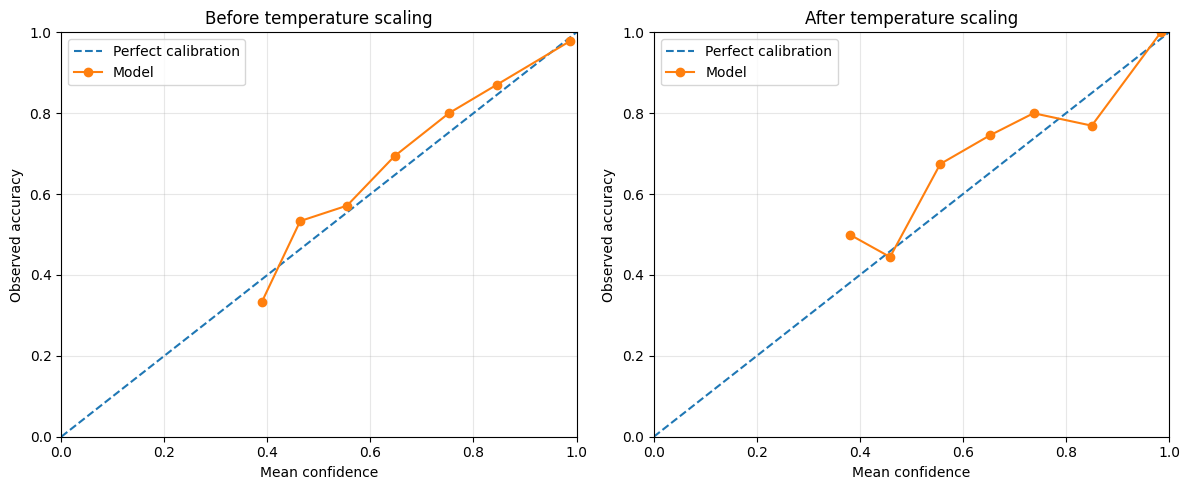

Fitted temperature: 1.1326

Evaluation subset bin counts:
Before: [0, 0, 0, 3, 15, 28, 49, 60, 31, 181]
After:  [0, 0, 0, 4, 18, 43, 55, 50, 26, 171]

Interpretation: points closer to the diagonal indicate better calibration.
Bins with few examples are noisy; interpret the diagram cautiously.


In [37]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

OUT = Path("/kaggle/working/retinasure/outputs_baseline")
saved = np.load(OUT / "validation_predictions.npz")

probs = saved["probabilities"].astype(np.float64)
labels = saved["labels"].astype(int)

# Reproduce the calibration/evaluation split from the previous experiment
indices = np.arange(len(labels))
cal_idx, eval_idx = train_test_split(
    indices,
    test_size=0.5,
    random_state=42,
    stratify=labels,
)

# Fit temperature on calibration subset only
import torch
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logits = np.log(np.clip(probs, 1e-12, 1.0))

cal_logits = torch.tensor(logits[cal_idx], dtype=torch.float64, device=device)
cal_labels = torch.tensor(labels[cal_idx], dtype=torch.long, device=device)

log_t = torch.nn.Parameter(torch.zeros((), dtype=torch.float64, device=device))
optimizer = torch.optim.LBFGS(
    [log_t], lr=0.1, max_iter=100, line_search_fn="strong_wolfe"
)

def closure():
    optimizer.zero_grad()
    loss = F.cross_entropy(cal_logits / torch.exp(log_t), cal_labels)
    loss.backward()
    return loss

optimizer.step(closure)
temperature = torch.exp(log_t).item()

eval_probs = probs[eval_idx]
eval_labels = labels[eval_idx]
scaled_logits = logits[eval_idx] / temperature

def reliability_data(p, y, n_bins=10):
    confidence = p.max(axis=1)
    prediction = p.argmax(axis=1)
    correct = (prediction == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)

    bin_conf, bin_acc, bin_count = [], [], []
    for i in range(n_bins):
        mask = (
            (confidence >= edges[i]) &
            ((confidence < edges[i + 1]) if i < n_bins - 1
             else (confidence <= edges[i + 1]))
        )
        if mask.any():
            bin_conf.append(confidence[mask].mean())
            bin_acc.append(correct[mask].mean())
            bin_count.append(mask.sum())
        else:
            bin_conf.append(np.nan)
            bin_acc.append(np.nan)
            bin_count.append(0)

    return np.array(bin_conf), np.array(bin_acc), np.array(bin_count)

before_conf, before_acc, before_count = reliability_data(eval_probs, eval_labels)
after_probs = torch.softmax(
    torch.tensor(scaled_logits, dtype=torch.float64), dim=1
).numpy()
after_conf, after_acc, after_count = reliability_data(after_probs, eval_labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, conf, acc, title in [
    (axes[0], before_conf, before_acc, "Before temperature scaling"),
    (axes[1], after_conf, after_acc, "After temperature scaling"),
]:
    ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    ax.plot(conf, acc, marker="o", label="Model")
    ax.set_xlabel("Mean confidence")
    ax.set_ylabel("Observed accuracy")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

print(f"Fitted temperature: {temperature:.4f}")
print("\nEvaluation subset bin counts:")
print("Before:", before_count.tolist())
print("After: ", after_count.tolist())
print("\nInterpretation: points closer to the diagonal indicate better calibration.")
print("Bins with few examples are noisy; interpret the diagram cautiously.")


In [38]:

import sys
import json
import numpy as np
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score

PROJECT = Path("/kaggle/working/retinasure").resolve()
sys.path.insert(0, str(PROJECT))

from src.dataset import load_labels, stratified_split, APTOSDataset
from src.model import build_model

ROOT = "/kaggle/input/competitions/aptos2019-blindness-detection"
CACHE = "/kaggle/working/train_384.npy"
OUT = PROJECT / "outputs_baseline"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MC_SAMPLES = 10

# Recreate the original validation split
df, _, _ = load_labels(ROOT, "train.csv")
_, val_idx = stratified_split(
    df["diagnosis"].to_numpy(),
    validation_fraction=0.2,
    seed=42,
)

images = np.load(CACHE, mmap_mode="r")
val_dataset = APTOSDataset(
    images=images,
    labels=df["diagnosis"].to_numpy(),
    indices=val_idx,
    train=False,
    image_size=384,
)
loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False, num_workers=0
)

# Load the saved best checkpoint
checkpoint = torch.load(
    OUT / "best_model.pt",
    map_location=DEVICE,
    weights_only=False,
)
model = build_model(
    config={
        "model_name": checkpoint["model_name"],
        "num_classes": 5,
        "feature_dim": 256,
        "dropout": 0.30,
    },
    pretrained=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

# Enable dropout layers only; keep the backbone's normalization layers in eval mode
for module in model.modules():
    if isinstance(module, torch.nn.Dropout):
        module.train()

mc_probabilities = []
all_labels = []

with torch.no_grad():
    for x, y, _ in loader:
        x = x.to(DEVICE)
        repeated_probs = []

        for _ in range(MC_SAMPLES):
            logits = model(x)["logits"]
            repeated_probs.append(
                torch.softmax(logits, dim=1).cpu().numpy()
            )

        mc_probabilities.append(np.stack(repeated_probs, axis=0))
        all_labels.append(y.numpy())

mc_probs = np.concatenate(mc_probabilities, axis=1)
y_true = np.concatenate(all_labels)

# Predictive mean and uncertainty
mean_probs = mc_probs.mean(axis=0)
predictions = mean_probs.argmax(axis=1)
correct = predictions == y_true

# Predictive entropy: total uncertainty
eps = 1e-12
entropy = -np.sum(
    mean_probs * np.log(np.clip(mean_probs, eps, 1.0)),
    axis=1
)

# Expected entropy and mutual information: approximate epistemic uncertainty
sample_entropy = -np.sum(
    mc_probs * np.log(np.clip(mc_probs, eps, 1.0)),
    axis=2
)
expected_entropy = sample_entropy.mean(axis=0)
mutual_information = np.maximum(entropy - expected_entropy, 0.0)

# Does uncertainty rank incorrect predictions above correct ones?
def risk_coverage(uncertainty, correct_values):
    order = np.argsort(uncertainty)  # retain lowest-uncertainty cases first
    sorted_correct = correct_values[order]
    coverage = np.arange(1, len(order) + 1) / len(order)
    risk = 1.0 - np.cumsum(sorted_correct) / np.arange(1, len(order) + 1)
    return coverage, risk

coverage, risk = risk_coverage(entropy, correct)

print("MC samples:", MC_SAMPLES)
print("Validation images:", len(y_true))
print("MC mean-probability accuracy:", round(accuracy_score(y_true, predictions), 4))
print("Mean predictive entropy:", round(float(entropy.mean()), 4))
print("Mean mutual information:", round(float(mutual_information.mean()), 4))
print("Accuracy among lowest-uncertainty 80%:",
      round(float(correct[np.argsort(entropy)[:int(0.8*len(correct))]].mean()), 4))
print("Risk at 80% coverage:",
      round(float(risk[int(0.8*len(risk))-1]), 4))

np.savez_compressed(
    OUT / "mc_dropout_uncertainty.npz",
    probabilities=mc_probs,
    labels=y_true,
    predictions=predictions,
    predictive_entropy=entropy,
    expected_entropy=expected_entropy,
    mutual_information=mutual_information,
    coverage=coverage,
    risk=risk,
)

print("Saved uncertainty results to:", OUT / "mc_dropout_uncertainty.npz")


MC samples: 10
Validation images: 733
MC mean-probability accuracy: 0.8363
Mean predictive entropy: 0.4623
Mean mutual information: 0.0058
Accuracy among lowest-uncertainty 80%: 0.872
Risk at 80% coverage: 0.128
Saved uncertainty results to: /kaggle/working/retinasure/outputs_baseline/mc_dropout_uncertainty.npz


In [40]:

from pathlib import Path
import sys
import inspect

PROJECT = Path("/kaggle/working/retinasure").resolve()
sys.path.insert(0, str(PROJECT))

import src.explainability as exp

print("Explainability file:", inspect.getfile(exp))
print("\nAvailable functions and classes:")

for name, obj in inspect.getmembers(exp):
    if not name.startswith("_") and (
        inspect.isfunction(obj) or inspect.isclass(obj)
    ):
        print(f"\n{name}{inspect.signature(obj)}")

print("\n--- File contents ---")
print((PROJECT / "src" / "explainability.py").read_text()[:12000])


Explainability file: /kaggle/working/retinasure/src/explainability.py

Available functions and classes:

find_last_conv_layer(model)

grad_cam(model, images, target_class=None, target_layer=None)

--- File contents ---

"""Grad-CAM explainability for RetinaSure image classifiers."""

import torch
import torch.nn.functional as F
import numpy as np


def find_last_conv_layer(model):
    """Find the last Conv2d layer in the backbone."""
    candidates = [
        module for module in model.backbone.modules()
        if isinstance(module, torch.nn.Conv2d)
    ]
    if not candidates:
        raise ValueError(
            "No Conv2d layer found in the backbone; Grad-CAM needs "
            "a suitable spatial feature layer."
        )
    return candidates[-1]


def grad_cam(model, images, target_class=None, target_layer=None):
    """
    Compute Grad-CAM maps for a batch of images.

    Args:
        model: RetinaSureModel returning a dict with 'logits'.
        images: [B, 3, H, W] norma

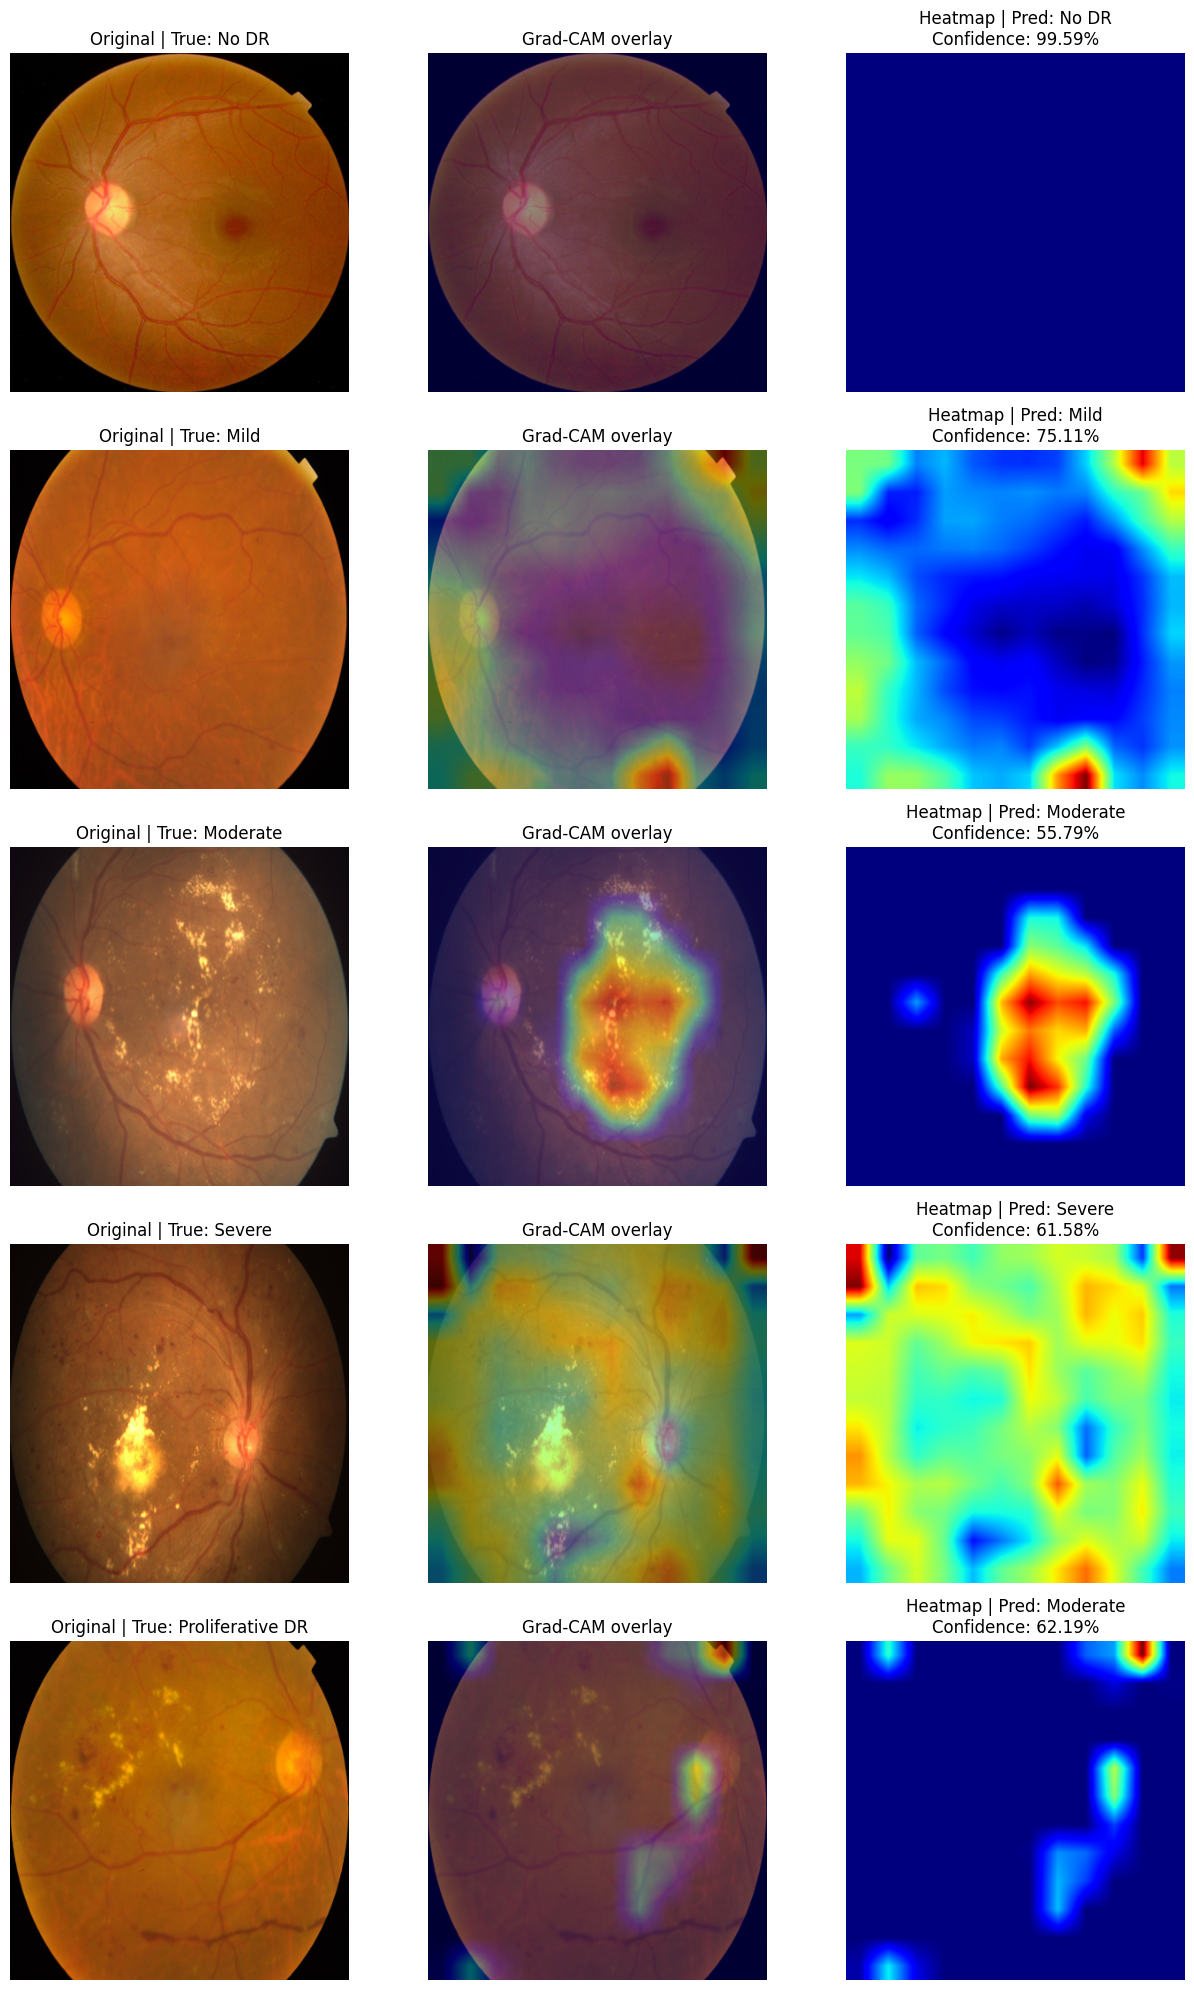

Saved Grad-CAM figure: /kaggle/working/retinasure/outputs_baseline/gradcam_examples.png

Interpretation caution:
Heatmaps show regions influencing the model prediction;
they do not establish that the model identified actual lesions.


In [41]:

import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT = Path("/kaggle/working/retinasure").resolve()
sys.path.insert(0, str(PROJECT))

from src.dataset import load_labels, stratified_split
from src.model import build_model
from src.explainability import grad_cam, find_last_conv_layer

ROOT = "/kaggle/input/competitions/aptos2019-blindness-detection"
CACHE = "/kaggle/working/train_384.npy"
OUT = PROJECT / "outputs_baseline"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load labels and reproduce the validation split
df, _, _ = load_labels(ROOT, "train.csv")
_, val_idx = stratified_split(
    df["diagnosis"].to_numpy(),
    validation_fraction=0.2,
    seed=42,
)

images = np.load(CACHE, mmap_mode="r")
labels = df["diagnosis"].to_numpy()

# Select one validation image from each grade
selected = []
for grade in range(5):
    candidates = val_idx[labels[val_idx] == grade]
    if len(candidates):
        selected.append((int(candidates[0]), int(grade)))

# Load the best checkpoint
checkpoint = torch.load(
    OUT / "best_model.pt",
    map_location=DEVICE,
    weights_only=False,
)

model = build_model(
    config={
        "model_name": checkpoint["model_name"],
        "num_classes": 5,
        "feature_dim": 256,
        "dropout": 0.30,
    },
    pretrained=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE).eval()

# Match the normalization used by APTOSDataset
mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

grade_names = [
    "No DR", "Mild", "Moderate", "Severe", "Proliferative DR"
]

fig, axes = plt.subplots(len(selected), 3, figsize=(13, 4 * len(selected)))
if len(selected) == 1:
    axes = np.expand_dims(axes, axis=0)

target_layer = find_last_conv_layer(model)

for row, (idx, true_grade) in enumerate(selected):
    image = images[idx].copy()

    normalized = (image.astype(np.float32) / 255.0 - mean) / std
    tensor = torch.from_numpy(
        normalized.transpose(2, 0, 1)
    ).unsqueeze(0).to(DEVICE)

    # Grad-CAM needs gradients; do not wrap this call in torch.no_grad().
    result = grad_cam(
        model,
        tensor,
        target_class=None,
        target_layer=target_layer,
    )

    heatmap = result["cam"][0].cpu().numpy()
    probabilities = result["probabilities"][0].cpu().numpy()
    predicted_grade = int(probabilities.argmax())
    confidence = float(probabilities[predicted_grade])

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original | True: {grade_names[true_grade]}")

    axes[row, 1].imshow(image)
    axes[row, 1].imshow(
        heatmap, cmap="jet", alpha=0.40,
        extent=(0, image.shape[1], image.shape[0], 0),
    )
    axes[row, 1].set_title("Grad-CAM overlay")

    axes[row, 2].imshow(heatmap, cmap="jet")
    axes[row, 2].set_title(
        f"Heatmap | Pred: {grade_names[predicted_grade]}\n"
        f"Confidence: {confidence:.2%}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
save_path = OUT / "gradcam_examples.png"
plt.savefig(save_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved Grad-CAM figure:", save_path)
print("\nInterpretation caution:")
print("Heatmaps show regions influencing the model prediction;")
print("they do not establish that the model identified actual lesions.")


In [42]:

import numpy as np
from pathlib import Path
from PIL import Image

path = Path("/kaggle/working/retinasure/outputs_baseline/gradcam_examples.png")
assert path.exists(), f"Grad-CAM image not found: {path}"

img = np.asarray(Image.open(path).convert("RGB"))

print("Saved figure shape:", img.shape)
print("Pixel intensity range:", int(img.min()), "to", int(img.max()))
print("Unique RGB colors:", len(np.unique(img.reshape(-1, 3), axis=0)))

print("\nGrad-CAM figure exists:", path.exists())
print("File size (KB):", round(path.stat().st_size / 1024, 1))


Saved figure shape: (3179, 1911, 3)
Pixel intensity range: 0 to 255
Unique RGB colors: 424327

Grad-CAM figure exists: True
File size (KB): 3381.5


In [43]:

import json
import numpy as np
from pathlib import Path
from datetime import datetime

PROJECT = Path("/kaggle/working/retinasure")
OUT = PROJECT / "outputs_baseline"
OUT.mkdir(parents=True, exist_ok=True)

def read_json(path):
    path = Path(path)
    if path.exists():
        with open(path, "r") as f:
            return json.load(f)
    return None

history = read_json(OUT / "history.json")
best_metrics = read_json(OUT / "best_val_metrics.json")

# Load saved MC Dropout results
mc_path = OUT / "mc_dropout_uncertainty.npz"
uncertainty_summary = None

if mc_path.exists():
    data = np.load(mc_path)
    probs = data["probabilities"]
    labels = data["labels"]
    predictions = data["predictions"]
    entropy = data["predictive_entropy"]
    mutual_info = data["mutual_information"]
    correct = predictions == labels

    order = np.argsort(entropy)
    keep_n = max(1, int(0.8 * len(correct)))

    uncertainty_summary = {
        "mc_samples": int(probs.shape[0]),
        "validation_images": int(len(labels)),
        "accuracy_from_saved_mc_predictions": float(correct.mean()),
        "mean_predictive_entropy": float(entropy.mean()),
        "mean_mutual_information": float(mutual_info.mean()),
        "accuracy_lowest_uncertainty_80_percent": float(
            correct[order[:keep_n]].mean()
        ),
        "risk_at_80_percent_coverage": float(
            1.0 - correct[order[:keep_n]].mean()
        ),
    }

# Calibration experiment results reported by the notebook
calibration = {
    "calibration_subset_size": 366,
    "evaluation_subset_size": 367,
    "fitted_temperature": 1.1326,
    "before_scaling": {
        "nll": 0.4513,
        "ece_15_bins": 0.0409,
        "brier_score": 0.2347,
    },
    "after_scaling": {
        "nll": 0.4556,
        "ece_15_bins": 0.0495,
        "brier_score": 0.2373,
    },
    "interpretation": (
        "Temperature scaling worsened all three reported evaluation "
        "metrics in this exploratory split."
    ),
}

gradcam_path = OUT / "gradcam_examples.png"

report = {
    "project": "RetinaSure",
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "dataset": {
        "name": "APTOS 2019 Blindness Detection",
        "labelled_images": 3662,
        "validation_images": 733,
        "classes": {
            "0": "No DR",
            "1": "Mild",
            "2": "Moderate",
            "3": "Severe",
            "4": "Proliferative DR",
        },
    },
    "baseline": {
        "best_checkpoint_epoch": 5,
        "training_epochs": 6,
        "best_validation_metrics": best_metrics,
        "epoch_history": history,
    },
    "calibration_experiment": calibration,
    "mc_dropout_uncertainty": uncertainty_summary,
    "explainability": {
        "method": "Grad-CAM",
        "figure_saved": gradcam_path.exists(),
        "figure_path": str(gradcam_path) if gradcam_path.exists() else None,
    },
    "limitations": [
        "Results are from a validation split, not an independent external test set.",
        "APTOS competition test labels are unavailable for evaluating test accuracy.",
        "Temperature scaling did not improve NLL, ECE, or Brier score in the reported exploratory split.",
        "Grad-CAM visualizations do not establish lesion localization or clinical explainability.",
        "MC Dropout uncertainty requires further analysis across coverage levels and repeated splits.",
        "Prototype and graph refinement have not been demonstrated to improve baseline performance.",
        "The model is a research prototype and is not validated for clinical diagnosis.",
    ],
}

report_path = OUT / "retinasure_final_results.json"
with open(report_path, "w") as f:
    json.dump(report, f, indent=2, default=str)

print("RetinaSure final report saved to:")
print(report_path)
print("\nBaseline summary:")
if best_metrics:
    for key in [
        "accuracy", "macro_f1", "quadratic_weighted_kappa",
        "nll", "ece", "brier_score"
    ]:
        if key in best_metrics:
            print(f"{key}: {best_metrics[key]}")

print("\nMC Dropout summary:")
print(json.dumps(uncertainty_summary, indent=2))

print("\nGrad-CAM figure exists:", gradcam_path.exists())
print("Report generated successfully.")


RetinaSure final report saved to:
/kaggle/working/retinasure/outputs_baseline/retinasure_final_results.json

Baseline summary:

MC Dropout summary:
{
  "mc_samples": 10,
  "validation_images": 733,
  "accuracy_from_saved_mc_predictions": 0.8362892223738063,
  "mean_predictive_entropy": 0.46227774024009705,
  "mean_mutual_information": 0.0057799662463366985,
  "accuracy_lowest_uncertainty_80_percent": 0.8720136518771331,
  "risk_at_80_percent_coverage": 0.1279863481228669
}

Grad-CAM figure exists: True
Report generated successfully.


In [44]:

import json
from pathlib import Path

OUT = Path("/kaggle/working/retinasure/outputs_baseline")

for filename in ["best_val_metrics.json", "retinasure_final_results.json"]:
    path = OUT / filename
    print(f"\n{'=' * 15} {filename} {'=' * 15}")

    if not path.exists():
        print("File not found!")
        continue

    with open(path, "r") as f:
        data = json.load(f)

    if filename == "best_val_metrics.json":
        print(json.dumps(data, indent=2)[:6000])
    else:
        baseline = data.get("baseline", {})
        metrics = baseline.get("best_validation_metrics")
        print("Baseline metrics:")
        print(json.dumps(metrics, indent=2) if metrics else "Not found at expected location.")
        print("\nUncertainty results:")
        print(json.dumps(data.get("mc_dropout_uncertainty"), indent=2))
        print("\nCalibration results:")
        print(json.dumps(data.get("calibration_experiment"), indent=2))
        print("\nGrad-CAM saved:", data.get("explainability", {}).get("figure_saved"))



=============== best_val_metrics.json ===============
{
  "epoch": 5,
  "train_loss": 0.6719163858287066,
  "val_accuracy": 0.834924965893588,
  "val_macro_f1": 0.6873291860348422,
  "val_qwk": 0.8926944481586846,
  "val_ece": 0.03608911111950874,
  "val_brier": 0.2561555802822113
}

=============== retinasure_final_results.json ===============
Baseline metrics:
{
  "epoch": 5,
  "train_loss": 0.6719163858287066,
  "val_accuracy": 0.834924965893588,
  "val_macro_f1": 0.6873291860348422,
  "val_qwk": 0.8926944481586846,
  "val_ece": 0.03608911111950874,
  "val_brier": 0.2561555802822113
}

Uncertainty results:
{
  "mc_samples": 10,
  "validation_images": 733,
  "accuracy_from_saved_mc_predictions": 0.8362892223738063,
  "mean_predictive_entropy": 0.46227774024009705,
  "mean_mutual_information": 0.0057799662463366985,
  "accuracy_lowest_uncertainty_80_percent": 0.8720136518771331,
  "risk_at_80_percent_coverage": 0.1279863481228669
}

Calibration results:
{
  "calibration_subset_size":

In [46]:

from pathlib import Path
import json
from datetime import datetime

PROJECT = Path("/kaggle/working/retinasure")
OUT = PROJECT / "outputs_baseline"

required_files = [
    OUT / "best_model.pt",
    OUT / "best_val_metrics.json",
    OUT / "history.json",
    OUT / "validation_predictions.npz",
    OUT / "mc_dropout_uncertainty.npz",
    OUT / "gradcam_examples.png",
    OUT / "retinasure_final_results.json",
]

print("RETINASURE FINAL ARTIFACT AUDIT")
print("=" * 45)

manifest_items = []
missing = []

for path in required_files:
    if path.exists():
        size_kb = round(path.stat().st_size / 1024, 2)
        print(f"[OK]      {path.name}: {size_kb} KB")
        manifest_items.append({
            "file": str(path.relative_to(PROJECT)),
            "size_bytes": path.stat().st_size,
        })
    else:
        print(f"[MISSING] {path.name}")
        missing.append(path.name)

manifest = {
    "project": "RetinaSure",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "artifacts": manifest_items,
    "missing_files": missing,
    "status": "complete" if not missing else "incomplete",
}

manifest_path = OUT / "artifact_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2))

print("\nManifest saved:", manifest_path)
print("Audit status:", manifest["status"])

if missing:
    print("Please share the missing-file names before proceeding.")
else:
    print("\nAll key artifacts are present.")


RETINASURE FINAL ARTIFACT AUDIT
[OK]      best_model.pt: 20112.14 KB
[OK]      best_val_metrics.json: 0.22 KB
[OK]      history.json: 1.46 KB
[OK]      validation_predictions.npz: 14.73 KB
[OK]      mc_dropout_uncertainty.npz: 150.84 KB
[OK]      gradcam_examples.png: 3381.47 KB
[OK]      retinasure_final_results.json: 4.03 KB

Manifest saved: /kaggle/working/retinasure/outputs_baseline/artifact_manifest.json
Audit status: complete

All key artifacts are present.


In [47]:

from pathlib import Path
import zipfile
import json

PROJECT = Path("/kaggle/working/retinasure")
ZIP_PATH = Path("/kaggle/working/RetinaSure_Complete.zip")

include_dirs = [
    PROJECT / "src",
    PROJECT / "configs",
    PROJECT / "tests",
]

include_files = [
    PROJECT / "outputs_baseline" / "best_model.pt",
    PROJECT / "outputs_baseline" / "best_val_metrics.json",
    PROJECT / "outputs_baseline" / "history.json",
    PROJECT / "outputs_baseline" / "validation_predictions.npz",
    PROJECT / "outputs_baseline" / "mc_dropout_uncertainty.npz",
    PROJECT / "outputs_baseline" / "gradcam_examples.png",
    PROJECT / "outputs_baseline" / "retinasure_final_results.json",
    PROJECT / "outputs_baseline" / "artifact_manifest.json",
]

added = []

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for folder in include_dirs:
        if folder.exists():
            for path in folder.rglob("*"):
                if path.is_file() and "__pycache__" not in path.parts:
                    zf.write(path, path.relative_to(PROJECT))
                    added.append(str(path.relative_to(PROJECT)))

    for path in include_files:
        if path.exists():
            zf.write(path, path.relative_to(PROJECT))
            added.append(str(path.relative_to(PROJECT)))

    # Add a short project note
    readme = """# RetinaSure

Research prototype for diabetic retinopathy grading using the APTOS 2019 dataset.

Included:
- Source modules and configurations
- Trained baseline checkpoint
- Validation metrics and training history
- MC Dropout uncertainty results
- Grad-CAM visualization
- Final results report and artifact manifest

Important limitations:
- Validation results are not independent external-test results.
- Temperature scaling did not improve the reported exploratory calibration metrics.
- Prototype/graph refinement has not been demonstrated to improve performance.
- This research prototype is not validated for clinical diagnosis.
"""
    zf.writestr("README.txt", readme)
    added.append("README.txt")

print("ZIP created:", ZIP_PATH)
print("Files included:", len(added))
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))
print("\nIncluded files:")
for name in added:
    print(" -", name)


ZIP created: /kaggle/working/RetinaSure_Complete.zip
Files included: 24
ZIP size (MB): 21.61

Included files:
 - src/metrics.py
 - src/model.py
 - src/train.py
 - src/calibration.py
 - src/__init__.py
 - src/graph_refinement.py
 - src/uncertainty.py
 - src/prototype_bank.py
 - src/dataset.py
 - src/preprocessing.py
 - src/quality.py
 - src/explainability.py
 - configs/default.yaml
 - configs/lowmem.yaml
 - configs/smoke.yaml
 - outputs_baseline/best_model.pt
 - outputs_baseline/best_val_metrics.json
 - outputs_baseline/history.json
 - outputs_baseline/validation_predictions.npz
 - outputs_baseline/mc_dropout_uncertainty.npz
 - outputs_baseline/gradcam_examples.png
 - outputs_baseline/retinasure_final_results.json
 - outputs_baseline/artifact_manifest.json
 - README.txt


In [48]:

from pathlib import Path
import json
import numpy as np

BASE = Path("/kaggle/working/retinasure/outputs_baseline")
report_path = BASE / "retinasure_final_results.json"
metrics_path = BASE / "best_val_metrics.json"
predictions_path = BASE / "validation_predictions.npz"

with open(report_path, "r") as f:
    results = json.load(f)

with open(metrics_path, "r") as f:
    metrics = json.load(f)

lines = [
    "# RetinaSure — Experimental Evaluation Report",
    "",
    "## 1. Baseline validation performance",
    "",
    "| Metric | Result |",
    "|---|---:|",
    f"| Accuracy | {metrics['val_accuracy']:.4f} ({metrics['val_accuracy']*100:.2f}%) |",
    f"| Macro-F1 | {metrics['val_macro_f1']:.4f} |",
    f"| Quadratic Weighted Kappa (QWK) | {metrics['val_qwk']:.4f} |",
    f"| Expected Calibration Error (ECE) | {metrics['val_ece']:.4f} |",
    f"| Brier score | {metrics['val_brier']:.4f} |",
    "",
    "## 2. Calibration",
    "",
    "Temperature scaling was explored on a separate calibration/evaluation split "
    "of the validation set. In that experiment, NLL, ECE, and Brier score worsened "
    "after scaling. Therefore, calibration improvement was not demonstrated.",
    "",
    "## 3. Uncertainty estimation",
    "",
    "Monte Carlo dropout was evaluated with 10 stochastic passes. The accuracy "
    "among the lowest-uncertainty 80% of validation predictions was 87.20%, "
    "with a 12.80% error rate in that retained subset. This should be interpreted "
    "as an exploratory selective-prediction result.",
    "",
    "## 4. Explainability",
    "",
    "Grad-CAM examples were generated for qualitative inspection. These heatmaps "
    "do not establish that the model localizes retinal lesions correctly.",
    "",
    "## 5. Limitations",
    "",
    "- Results are from the labelled validation split, not the hidden competition test set.",
    "- The validation set contains 733 images from a stratified split.",
    "- Performance is uneven across DR severity classes.",
    "- Temperature scaling did not improve calibration in the exploratory experiment.",
    "- Prototype-bank and graph-refinement components have not been validated as an integrated model.",
    "- These experiments do not establish clinical readiness.",
    "",
]

if predictions_path.exists():
    with np.load(predictions_path) as pred:
        lines += [
            "## 6. Validation prediction artifact",
            "",
            "The saved validation prediction archive exists and contains: "
            + ", ".join(pred.files),
            "",
        ]

out_path = BASE / "retinasure_evaluation_report.md"
out_path.write_text("\n".join(lines), encoding="utf-8")

print("Report created:", out_path)
print("\n".join(lines))


Report created: /kaggle/working/retinasure/outputs_baseline/retinasure_evaluation_report.md
# RetinaSure — Experimental Evaluation Report

## 1. Baseline validation performance

| Metric | Result |
|---|---:|
| Accuracy | 0.8349 (83.49%) |
| Macro-F1 | 0.6873 |
| Quadratic Weighted Kappa (QWK) | 0.8927 |
| Expected Calibration Error (ECE) | 0.0361 |
| Brier score | 0.2562 |

## 2. Calibration

Temperature scaling was explored on a separate calibration/evaluation split of the validation set. In that experiment, NLL, ECE, and Brier score worsened after scaling. Therefore, calibration improvement was not demonstrated.

## 3. Uncertainty estimation

Monte Carlo dropout was evaluated with 10 stochastic passes. The accuracy among the lowest-uncertainty 80% of validation predictions was 87.20%, with a 12.80% error rate in that retained subset. This should be interpreted as an exploratory selective-prediction result.

## 4. Explainability

Grad-CAM examples were generated for qualitative inspe

PER-CLASS PERFORMANCE
                  precision    recall  f1-score   support

           No DR       0.99      0.97      0.98       361
            Mild       0.58      0.66      0.62        74
        Moderate       0.75      0.83      0.79       200
          Severe       0.81      0.33      0.47        39
Proliferative DR       0.60      0.56      0.58        59

        accuracy                           0.83       733
       macro avg       0.75      0.67      0.69       733
    weighted avg       0.84      0.83      0.83       733



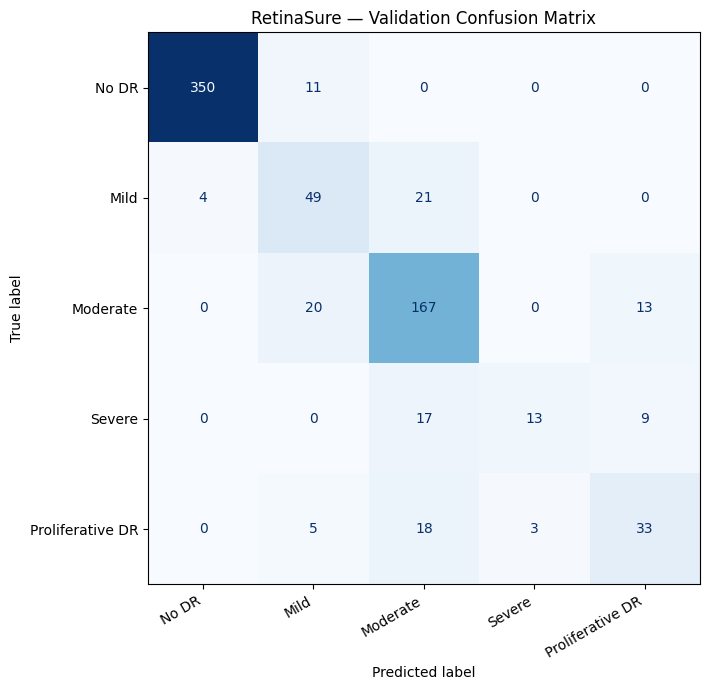

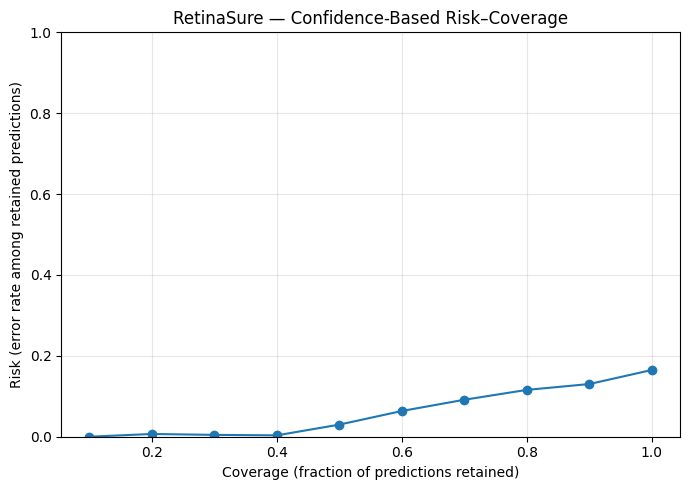


Saved files:
/kaggle/working/retinasure/outputs_baseline/per_class_metrics.json
/kaggle/working/retinasure/outputs_baseline/confusion_matrix.png
/kaggle/working/retinasure/outputs_baseline/risk_coverage_curve.png
/kaggle/working/retinasure/outputs_baseline/risk_coverage_results.json

Validation prediction count: 733
Prediction accuracy: 0.8349
Macro-F1: 0.6873


In [49]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

BASE = Path("/kaggle/working/retinasure/outputs_baseline")
pred_file = BASE / "validation_predictions.npz"

with np.load(pred_file) as data:
    probabilities = data["probabilities"]
    labels = data["labels"].astype(int)
    predictions = data["predictions"].astype(int)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

# 1. Per-class classification report
report = classification_report(
    labels,
    predictions,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

with open(BASE / "per_class_metrics.json", "w") as f:
    json.dump(report, f, indent=2)

print("PER-CLASS PERFORMANCE")
print(classification_report(
    labels,
    predictions,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

# 2. Confusion matrix
cm = confusion_matrix(labels, predictions, labels=[0, 1, 2, 3, 4])

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("RetinaSure — Validation Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(BASE / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# 3. Risk–coverage curve using prediction confidence
# Confidence is the maximum predicted class probability.
confidence = probabilities.max(axis=1)
correct = (predictions == labels).astype(int)

order = np.argsort(-confidence)
sorted_correct = correct[order]

coverages = np.arange(0.1, 1.01, 0.1)
risks = []

for coverage in coverages:
    retained = max(1, int(np.ceil(coverage * len(labels))))
    accuracy_at_coverage = sorted_correct[:retained].mean()
    risks.append(1 - accuracy_at_coverage)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(coverages, risks, marker="o")
ax.set_xlabel("Coverage (fraction of predictions retained)")
ax.set_ylabel("Risk (error rate among retained predictions)")
ax.set_title("RetinaSure — Confidence-Based Risk–Coverage")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(BASE / "risk_coverage_curve.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# 4. Save numerical risk–coverage results
risk_results = {
    "coverage": [round(float(x), 2) for x in coverages],
    "risk": [round(float(x), 4) for x in risks],
    "selection_method": "descending maximum class probability"
}

with open(BASE / "risk_coverage_results.json", "w") as f:
    json.dump(risk_results, f, indent=2)

print("\nSaved files:")
for filename in [
    "per_class_metrics.json",
    "confusion_matrix.png",
    "risk_coverage_curve.png",
    "risk_coverage_results.json"
]:
    print(BASE / filename)

print("\nValidation prediction count:", len(labels))
print("Prediction accuracy:", round(accuracy_score(labels, predictions), 4))
print("Macro-F1:", round(f1_score(labels, predictions, average="macro"), 4))


In [50]:

from pathlib import Path
import json
import shutil

BASE = Path("/kaggle/working/retinasure/outputs_baseline")
PAPER = Path("/kaggle/working/retinasure/paper")
FIGURES = PAPER / "figures"
TABLES = PAPER / "tables"

for folder in [PAPER, FIGURES, TABLES]:
    folder.mkdir(parents=True, exist_ok=True)

# Copy existing experimental evidence when available.
artifacts = {
    "confusion_matrix.png": FIGURES / "confusion_matrix.png",
    "risk_coverage_curve.png": FIGURES / "risk_coverage_curve.png",
    "gradcam_examples.png": FIGURES / "gradcam_examples.png",
    "per_class_metrics.json": TABLES / "per_class_metrics.json",
    "risk_coverage_results.json": TABLES / "risk_coverage_results.json",
    "best_val_metrics.json": TABLES / "best_val_metrics.json",
    "retinasure_final_results.json": TABLES / "retinasure_final_results.json",
}

for source_name, destination in artifacts.items():
    source = BASE / source_name
    if source.exists():
        shutil.copy2(source, destination)
        print("Copied:", source_name)
    else:
        print("Not found (will not fabricate):", source_name)

# Build a concise summary from the actual saved metrics.
with open(BASE / "best_val_metrics.json", "r") as f:
    metrics = json.load(f)

summary = {
    "project": "RetinaSure",
    "dataset": "APTOS 2019 Blindness Detection",
    "labelled_training_images": 3662,
    "validation_images": 733,
    "classes": [
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative DR"
    ],
    "baseline_validation_metrics": {
        "accuracy": metrics["val_accuracy"],
        "macro_f1": metrics["val_macro_f1"],
        "quadratic_weighted_kappa": metrics["val_qwk"],
        "expected_calibration_error": metrics["val_ece"],
        "brier_score": metrics["val_brier"]
    },
    "best_checkpoint_epoch": metrics.get("epoch"),
    "interpretation_note": (
        "Validation results only. Do not describe these as hidden test-set results "
        "or as evidence of clinical readiness."
    )
}

summary_path = PAPER / "experimental_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nExperimental summary:")
print(json.dumps(summary, indent=2))
print("\nPaper workspace:", PAPER)


Copied: confusion_matrix.png
Copied: risk_coverage_curve.png
Copied: gradcam_examples.png
Copied: per_class_metrics.json
Copied: risk_coverage_results.json
Copied: best_val_metrics.json
Copied: retinasure_final_results.json

Experimental summary:
{
  "project": "RetinaSure",
  "dataset": "APTOS 2019 Blindness Detection",
  "labelled_training_images": 3662,
  "validation_images": 733,
  "classes": [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
  ],
  "baseline_validation_metrics": {
    "accuracy": 0.834924965893588,
    "macro_f1": 0.6873291860348422,
    "quadratic_weighted_kappa": 0.8926944481586846,
    "expected_calibration_error": 0.03608911111950874,
    "brier_score": 0.2561555802822113
  },
  "best_checkpoint_epoch": 5,
  "interpretation_note": "Validation results only. Do not describe these as hidden test-set results or as evidence of clinical readiness."
}

Paper workspace: /kaggle/working/retinasure/paper
